In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import gc, json, random, csv, os
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import binary_dilation
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator

ROOT = Path('/content/drive/MyDrive/EdgeTB_Project')
CLEAN = ROOT/'datasets_clean'
UNET_PATH = ROOT/'models/unet_lung.h5'
OLD_WIDE = ROOT/'models/final/mobilenetv2_lungs_wide.h5'
EXT_NPZ = ROOT/'results/tbx11k_eval_nearest.npz'
WORK = ROOT/'wide_mask_study'
CACHE = WORK/'cache'
MODELS = WORK/'models'
RESULTS = WORK/'results'
for d in (WORK,CACHE,MODELS,RESULTS): d.mkdir(parents=True, exist_ok=True)

SIZE=224
GROW=8
BATCH=32
SEEDS=[42,52,62]  # all runs will use identical training settings
# Keep identical first-run settings for direct comparisons: frozen ImageNet backbone,
# 20 epochs max, patience 5, Adam 0.001, batch 32, augmentation as in original notebook.
EPOCHS=20
PATIENCE=5
LR=1e-3
EXT_CACHE = CACHE/'external_wide_gray_uint8.npy'
print('TensorFlow:',tf.__version__)
print('Work folder:',WORK)
print('Existing wide model:',OLD_WIDE.exists())
print('Saved external test arrays:',EXT_NPZ.exists())
assert CLEAN.exists() and UNET_PATH.exists(), 'Missing datasets_clean or U-Net file. Check your Drive folder.'
assert EXT_NPZ.exists(), 'Missing results/tbx11k_eval_nearest.npz; recreate the fixed external evaluation file from the old notebook.'

TensorFlow: 2.21.0
Work folder: /content/drive/MyDrive/EdgeTB_Project/wide_mask_study
Existing wide model: True
Saved external test arrays: True


In [ ]:
OK={'.png','.jpg','.jpeg'}
def listing(split):
    ps, labels = [], []
    for folder, label in [('Normal',0),('TB',1)]:
        d=CLEAN/split/folder
        assert d.is_dir(), f'Missing folder {d}'
        for p in sorted(d.iterdir()):
            if p.suffix.lower() in OK:
                ps.append(p); labels.append(label)
    return ps, np.asarray(labels,dtype=np.int32)

ptr,ytr=listing('train')
pva,yva=listing('val')
pte,yte=listing('test')
assert (len(ptr),len(pva),len(pte))==(2927,627,628), 'Unexpected clean-split counts. Stop and check which cleaned dataset you mounted.'
assert set(np.unique(ytr))=={0,1}
print('Kaggle clean split:',[(name,len(x),int(yy.sum())) for name,x,yy in [('train',ptr,ytr),('val',pva,yva),('test',pte,yte)]])

with np.load(EXT_NPZ) as z:
    external_images = z['x']
    yext = z['y'].astype(np.int32)
    active = z['active'] if 'active' in z.files else None
assert external_images.ndim==4 and external_images.shape[1:]==(224,224,3)
assert len(external_images)==len(yext)==800 and set(np.unique(yext))=={0,1}, 'Check external file and labels.'
print('TBX11K external:',len(yext),'TB:',int(yext.sum()),'healthy:',int((yext==0).sum()))
print('Note: the TBX11K sick/other-disease group is NOT used in this two-class test.')

Kaggle clean split: [('train', 2927, 477), ('val', 627, 102), ('test', 628, 103)]
TBX11K external: 800 TB: 400 healthy: 400
Note: the TBX11K sick/other-disease group is NOT used in this two-class test.


In [ ]:

def dice_loss(y_true,y_pred):
    smooth=1e-6
    intersection=tf.reduce_sum(y_true*y_pred)
    return 1-(2*intersection+smooth)/(tf.reduce_sum(y_true)+tf.reduce_sum(y_pred)+smooth)

unet=load_model(str(UNET_PATH),custom_objects={'dice_loss':dice_loss},compile=False)
print('U-Net input:',unet.input_shape)

def mask_gray_batch(gray224):
    """Match old notebook: PIL 224=>256 (default resize), U-Net mask >.5,
    PIL nearest resize back to 224, dilate eight iterations, multiply grayscale."""
    img256 = np.stack([
        np.asarray(Image.fromarray(a).resize((256,256)),dtype=np.float32)/255.
        for a in gray224
    ])[...,None]
    pred=unet.predict(img256,batch_size=BATCH,verbose=0)[...,0] > 0.5
    outs=[]
    for a,m in zip(gray224,pred):
        m224=np.asarray(Image.fromarray(m.astype('uint8')*255).resize((224,224)))>127
        wide=binary_dilation(m224,iterations=GROW)
        outs.append(a*wide.astype('uint8'))
    return np.stack(outs).astype('uint8')

def image_gray_from_paths(paths):
    return np.stack([
        np.asarray(Image.open(p).convert('L').resize((224,224)),dtype='uint8')
        for p in paths
    ])

def image_gray_from_rgb(arr):
    return np.stack([np.asarray(Image.fromarray(a).convert('L'),dtype='uint8') for a in arr])

def build_cache(dst,count,input_reader):
    if dst.exists():
        arr=np.load(dst,mmap_mode='r')
        assert arr.shape==(count,224,224), f'Cache dimensions do not match: {dst}; remove/rename old cache after checking.'
        print('REUSED:',dst,arr.shape)
        return arr
    tmp=dst.with_suffix('.building.npy')
    # Explicit partial file is not considered a cache; overwrite on a retry.
    arr=np.lib.format.open_memmap(tmp,mode='w+',dtype='uint8',shape=(count,224,224))
    for start in range(0,count,BATCH):
        gray=input_reader(start,min(start+BATCH,count))
        arr[start:start+len(gray)]=mask_gray_batch(gray)
        arr.flush()
        if start%320==0:print(dst.name,start,'/',count)
    del arr
    os.replace(tmp,dst)
    print('SAVED:',dst)
    return np.load(dst,mmap_mode='r')

U-Net input: (None, 256, 256, 1)


In [ ]:

Xtr = build_cache(CACHE/'train_wide_gray_uint8.npy',len(ptr),lambda a,b:image_gray_from_paths(ptr[a:b]))
Xva = build_cache(CACHE/'val_wide_gray_uint8.npy',len(pva),lambda a,b:image_gray_from_paths(pva[a:b]))
Xte = build_cache(CACHE/'test_wide_gray_uint8.npy',len(pte),lambda a,b:image_gray_from_paths(pte[a:b]))
Xext= build_cache(EXT_CACHE,len(yext),lambda a,b:image_gray_from_rgb(external_images[a:b]))

print('Ready. Cache shapes:',Xtr.shape,Xva.shape,Xte.shape,Xext.shape)

train_wide_gray_uint8.npy 0 / 2927
train_wide_gray_uint8.npy 320 / 2927
train_wide_gray_uint8.npy 640 / 2927
train_wide_gray_uint8.npy 960 / 2927
train_wide_gray_uint8.npy 1280 / 2927
train_wide_gray_uint8.npy 1600 / 2927
train_wide_gray_uint8.npy 1920 / 2927
train_wide_gray_uint8.npy 2240 / 2927
train_wide_gray_uint8.npy 2560 / 2927
train_wide_gray_uint8.npy 2880 / 2927
SAVED: /content/drive/MyDrive/EdgeTB_Project/wide_mask_study/cache/train_wide_gray_uint8.npy
val_wide_gray_uint8.npy 0 / 627
val_wide_gray_uint8.npy 320 / 627
SAVED: /content/drive/MyDrive/EdgeTB_Project/wide_mask_study/cache/val_wide_gray_uint8.npy
test_wide_gray_uint8.npy 0 / 628
test_wide_gray_uint8.npy 320 / 628
SAVED: /content/drive/MyDrive/EdgeTB_Project/wide_mask_study/cache/test_wide_gray_uint8.npy
external_wide_gray_uint8.npy 0 / 800
external_wide_gray_uint8.npy 320 / 800
external_wide_gray_uint8.npy 640 / 800
SAVED: /content/drive/MyDrive/EdgeTB_Project/wide_mask_study/cache/external_wide_gray_uint8.npy
Ready

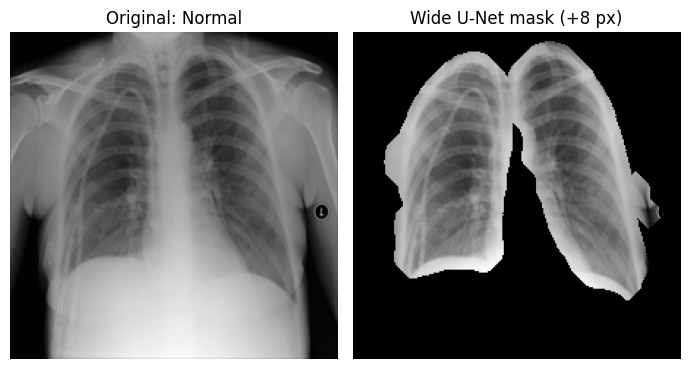

In [ ]:
# Visually check one test image against the original and verify labels/order.
k=0
orig=np.asarray(Image.open(pte[k]).convert('L').resize((224,224)))
fig,ax=plt.subplots(1,2,figsize=(7,4))
ax[0].imshow(orig,cmap='gray');ax[0].set_title(f'Original: {"TB" if yte[k] else "Normal"}')
ax[1].imshow(Xte[k],cmap='gray');ax[1].set_title('Wide U-Net mask (+8 px)')
for a in ax:a.axis('off')
fig.patch.set_facecolor('white');plt.tight_layout()
fig.savefig(RESULTS/'segmentation_example.png',dpi=200,facecolor='white')
plt.show()

In [ ]:
def input_batches(X, batch_size=32):
    for i in range(0,len(X),batch_size):
        # Old model was trained on triplicated 8-bit grayscale and scaled by 1/255.
        b=np.asarray(X[i:i+batch_size],dtype='float32')/255.
        yield np.repeat(b[...,None],3,axis=-1)

def predict_scores(m,X):
    return np.concatenate([
        np.asarray(m.predict(batch,verbose=0)).reshape(-1)
        for batch in input_batches(X)
    ])

def choose_threshold(y,p,target=None):
    fpr,tpr,th=roc_curve(y,p)
    valid=np.isfinite(th)
    if target is None:
        idx=np.argmax(np.where(valid,tpr-fpr,-np.inf))
    else:
        meets=np.where((tpr>=target)&valid)[0]
        if not len(meets):raise ValueError('Target validation sensitivity not reachable')
        # Among thresholds meeting desired sensitivity, take the one with lowest FPR.
        idx=meets[np.argmin(fpr[meets])]
    return float(th[idx])

def measures(y,p,t):
    tn,fp,fn,tp=confusion_matrix(y,p>=t,labels=[0,1]).ravel()
    return {'AUC':float(roc_auc_score(y,p)),
            'Sensitivity':float(tp/(tp+fn)) if (tp+fn) else float('nan'),
            'Specificity':float(tn/(tn+fp)) if (tn+fp) else float('nan'),
            'TP':int(tp),'FN':int(fn),'TN':int(tn),'FP':int(fp)}

def evaluate_and_save(m,name):
    pv=predict_scores(m,Xva); pt=predict_scores(m,Xte); pe=predict_scores(m,Xext)
    thresholds={'Validation Youden':choose_threshold(yva,pv),
                'Validation >=90% sensitivity':choose_threshold(yva,pv,.90),
                'Validation >=95% sensitivity':choose_threshold(yva,pv,.95)}
    rows=[]
    for threshold_name,t in thresholds.items():
        for dataset,yy,pp in [('Kaggle validation',yva,pv),('Kaggle test',yte,pt),('TBX11K external test',yext,pe)]:
            rows.append({'model':name,'threshold_source':threshold_name,'threshold':t,
                         'dataset':dataset,**measures(yy,pp,t)})
    df=pd.DataFrame(rows)
    df.to_csv(RESULTS/f'{name}_metrics.csv',index=False)
    np.savez_compressed(RESULTS/f'{name}_predictions.npz',
                        yval=yva,pval=pv,ytest=yte,ptest=pt,yexternal=yext,pexternal=pe)
    (RESULTS/f'{name}_thresholds.json').write_text(json.dumps(thresholds,indent=2))
    print('Saved scores, metrics, thresholds for:',name)
    display(df[df.dataset=='TBX11K external test'].round(4))
    return df,thresholds,(pv,pt,pe)

In [ ]:
if not OLD_WIDE.exists():
    print('Old wide-mask checkpoint not found.')
else:
    old_model=load_model(str(OLD_WIDE),compile=False)
    existing_table,existing_thresholds,existing_scores=evaluate_and_save(old_model,'wide_original_saved')
    print('Existing checkpoint external AUC:',roc_auc_score(yext,existing_scores[2]))


Saved scores, metrics, thresholds for: wide_original_saved


,model,threshold_source,threshold,dataset,AUC,Sensitivity,Specificity,TP,FN,TN,FP
2,wide_original_saved,Validation Youden,0.3485,TBX11K external test,0.8218,0.2075,0.9875,83,317,395,5
5,wide_original_saved,Validation >=90% sensitivity,0.3068,TBX11K external test,0.8218,0.2300,0.9850,92,308,394,6
8,wide_original_saved,Validation >=95% sensitivity,0.1642,TBX11K external test,0.8218,0.3950,0.9350,158,242,374,26


Existing checkpoint external AUC: 0.8218437499999999


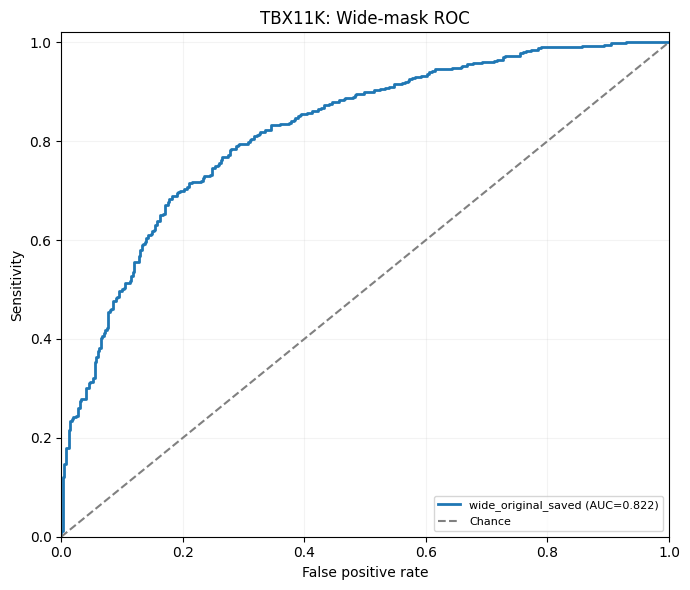

In [ ]:
# Single external ROC figure
fig,ax=plt.subplots(figsize=(7,6))
for f in sorted(RESULTS.glob('*_predictions.npz')):
    with np.load(f) as d:
        if len(d['yexternal'])!=800:continue
        yy=d['yexternal']; pp=d['pexternal']
        fpr,tpr,_=roc_curve(yy,pp)
        ax.plot(fpr,tpr,lw=2,label=f'{f.stem.replace("_predictions","")} (AUC={roc_auc_score(yy,pp):.3f})')
ax.plot([0,1],[0,1],'--',color='gray',label='Chance')
ax.set(xlabel='False positive rate',ylabel='Sensitivity',title='TBX11K: Wide-mask ROC',xlim=(0,1),ylim=(0,1.02))
ax.legend(fontsize=8,loc='lower right');ax.grid(alpha=.15)
plt.tight_layout();fig.savefig(RESULTS/'wide_mask_external_ROC.png',dpi=300,facecolor='white');plt.show()

In [ ]:
class GrayWideSequence(tf.keras.utils.Sequence):
    def __init__(self,X,y,training=False,seed=42,batch_size=32):
        self.X,self.y,self.training,self.batch_size=X,np.asarray(y),training,batch_size
        self.order=np.arange(len(y))
        self.rng=np.random.default_rng(seed)
        self.aug=ImageDataGenerator(rotation_range=10,width_shift_range=.05,
                                    height_shift_range=.05,zoom_range=.05,
                                    horizontal_flip=True) if training else None
        if training:self.on_epoch_end()
    def __len__(self):return int(np.ceil(len(self.y)/self.batch_size))
    def __getitem__(self,i):
        ids=self.order[i*self.batch_size:(i+1)*self.batch_size]
        raw=np.asarray(self.X[ids],dtype='float32')/255.
        batch=np.repeat(raw[...,None],3,axis=-1)
        if self.training:
            for k in range(len(batch)):
                # ImageDataGenerator random_transform expects float (H,W,C).
                batch[k]=self.aug.random_transform(batch[k])
        return batch,self.y[ids].astype('float32')
    def on_epoch_end(self):
        if self.training:self.rng.shuffle(self.order)

def train_one(seed):
    tf.keras.backend.clear_session()
    random.seed(seed);np.random.seed(seed);tf.random.set_seed(seed)
    train=GrayWideSequence(Xtr,ytr,training=True,seed=seed,batch_size=BATCH)
    val=GrayWideSequence(Xva,yva,training=False,batch_size=BATCH)
    base=MobileNetV2(weights='imagenet',include_top=False,input_shape=(SIZE,SIZE,3))
    base.trainable=False
    z=layers.Dropout(.3)(layers.GlobalAveragePooling2D()(base.output))
    output=layers.Dense(1,activation='sigmoid')(z)
    m=Model(base.input,output)
    m.compile(optimizer=Adam(LR),loss='binary_crossentropy')
    n_tb=int(ytr.sum());n_nm=int((ytr==0).sum())
    weights={0:len(ytr)/(2*n_nm),1:len(ytr)/(2*n_tb)}
    checkpoint=MODELS/f'wide_seed{seed}.keras'
    hist=m.fit(train,validation_data=val,epochs=EPOCHS,class_weight=weights,verbose=2,
               callbacks=[EarlyStopping(monitor='val_loss',patience=PATIENCE,restore_best_weights=True),
                          ModelCheckpoint(str(checkpoint),monitor='val_loss',save_best_only=True)])
    (RESULTS/f'wide_seed{seed}_history.json').write_text(json.dumps({k:[float(v) for v in vs] for k,vs in hist.history.items()},indent=2))
    best=load_model(str(checkpoint),compile=False)
    return best,checkpoint

In [ ]:

RUN_TRAINING=True  # change to True to train 42, 52 and 62
if RUN_TRAINING:
    for seed in SEEDS:
        name=f'wide_seed{seed}'
        checkpoint=MODELS/f'{name}.keras'
        metrics_file=RESULTS/f'{name}_metrics.csv'
        if checkpoint.exists() and metrics_file.exists():
            print('SKIPPING completed run:',name)
            continue
        if checkpoint.exists():
            print('Model exists, only evaluating:',name)
            best=load_model(str(checkpoint),compile=False)
        else:
            best,_=train_one(seed)
        evaluate_and_save(best,name)
        del best
        tf.keras.backend.clear_session();gc.collect()
else:
    print('No training performed. Set RUN_TRAINING=True when ready.')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
92/92 - 195s - 2s/step - loss: 0.3926 - val_loss: 0.3547
Epoch 2/20
92/92 - 204s - 2s/step - loss: 0.2926 - val_loss: 0.3204
Epoch 3/20
92/92 - 195s - 2s/step - loss: 0.2488 - val_loss: 0.3641
Epoch 4/20
92/92 - 193s - 2s/step - loss: 0.2213 - val_loss: 0.2090
Epoch 5/20
92/92 - 192s - 2s/step - loss: 0.2258 - val_loss: 0.2898
Epoch 6/20
92/92 - 191s - 2s/step - loss: 0.2137 - val_loss: 0.2282
Epoch 7/20
92/92 - 190s - 2s/step - loss: 0.2031 - val_loss: 0.2251
Epoch 8/20
92/92 - 191s - 2s/step - loss: 0.1989 - val_loss: 0.2049
Epoch 9/20
92/92 - 191s - 2s/step - loss: 0.1945 - val_loss: 0.3371
Epoch 10/20
92/92 - 202s - 2s/step - loss: 0.1895 - val_loss: 0.2652
Epoch 11/20
92/92 - 190s - 2s/step - loss: 0.1688 - val_loss: 0.2366
Epoch 12/20
92/92 - 190s - 2s/step - loss: 0.1820 - val_loss: 0.2481
Epoch 13/20
92/92 - 192s - 2s/step - loss: 0.1727 - val_loss: 0.3259
Saved scores, metrics, thresholds for: wide_seed42


,model,threshold_source,threshold,dataset,AUC,Sensitivity,Specificity,TP,FN,TN,FP
2,wide_seed42,Validation Youden,0.4304,TBX11K external test,0.7603,0.1325,0.9850,53,347,394,6
5,wide_seed42,Validation >=90% sensitivity,0.3343,TBX11K external test,0.7603,0.1825,0.9825,73,327,393,7
8,wide_seed42,Validation >=95% sensitivity,0.1321,TBX11K external test,0.7603,0.3775,0.9175,151,249,367,33


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
92/92 - 200s - 2s/step - loss: 0.4299 - val_loss: 0.3426
Epoch 2/20
92/92 - 198s - 2s/step - loss: 0.2997 - val_loss: 0.3905
Epoch 3/20
92/92 - 192s - 2s/step - loss: 0.2793 - val_loss: 0.4974
Epoch 4/20
92/92 - 208s - 2s/step - loss: 0.2454 - val_loss: 0.4530
Epoch 5/20
92/92 - 191s - 2s/step - loss: 0.2321 - val_loss: 0.4139
Epoch 6/20
92/92 - 204s - 2s/step - loss: 0.2172 - val_loss: 0.3862
Saved scores, metrics, thresholds for: wide_seed52


,model,threshold_source,threshold,dataset,AUC,Sensitivity,Specificity,TP,FN,TN,FP
2,wide_seed52,Validation Youden,0.4721,TBX11K external test,0.8182,0.1425,0.9950,57,343,398,2
5,wide_seed52,Validation >=90% sensitivity,0.3137,TBX11K external test,0.8182,0.2750,0.9750,110,290,390,10
8,wide_seed52,Validation >=95% sensitivity,0.2046,TBX11K external test,0.8182,0.4250,0.9325,170,230,373,27


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
92/92 - 214s - 2s/step - loss: 0.3928 - val_loss: 0.3198
Epoch 2/20
92/92 - 194s - 2s/step - loss: 0.2888 - val_loss: 0.3577
Epoch 3/20
92/92 - 206s - 2s/step - loss: 0.2714 - val_loss: 0.2875
Epoch 4/20
92/92 - 193s - 2s/step - loss: 0.2349 - val_loss: 0.3730
Epoch 5/20
92/92 - 208s - 2s/step - loss: 0.2240 - val_loss: 0.2745
Epoch 6/20
92/92 - 193s - 2s/step - loss: 0.2156 - val_loss: 0.4108
Epoch 7/20
92/92 - 192s - 2s/step - loss: 0.2144 - val_loss: 0.3093
Epoch 8/20
92/92 - 208s - 2s/step - loss: 0.2045 - val_loss: 0.2489
Epoch 9/20
92/92 - 196s - 2s/step - loss: 0.1965 - val_loss: 0.2291
Epoch 10/20
92/92 - 205s - 2s/step - loss: 0.1844 - val_loss: 0.2951
Epoch 11/20
92/92 - 193s - 2s/step - loss: 0.1954 - val_loss: 0.2823
Epoch 12/20
92/92 - 194s - 2s/step - loss: 0.1829 - val_loss: 0.3262
Epoch 13/20
92/92 - 192s - 2s/step - loss: 0.1734 - val_loss: 0.2357
Epoch 14/20
92/92 - 192s - 2s/step - loss: 0.1813 - val_loss: 0.3055
Saved scores, metrics, thresholds for: wide

,model,threshold_source,threshold,dataset,AUC,Sensitivity,Specificity,TP,FN,TN,FP
2,wide_seed62,Validation Youden,0.4462,TBX11K external test,0.7504,0.1950,0.965,78,322,386,14
5,wide_seed62,Validation >=90% sensitivity,0.4462,TBX11K external test,0.7504,0.1950,0.965,78,322,386,14
8,wide_seed62,Validation >=95% sensitivity,0.1622,TBX11K external test,0.7504,0.4325,0.880,173,227,352,48


In [ ]:
# Summary of independently saved seed metrics
files=sorted(RESULTS.glob('wide_seed*_metrics.csv'))
if files:
    all_df=pd.concat([pd.read_csv(f) for f in files],ignore_index=True)
    subset=all_df[(all_df.dataset=='TBX11K external test') &
                  (all_df.threshold_source=='Validation Youden')]
    display(subset[['model','AUC','Sensitivity','Specificity','FN','FP']].round(4))
    print('AUC across repeated seeds: mean=',round(subset.AUC.mean(),4),
          ' SD=',round(subset.AUC.std(ddof=1),4) if len(subset)>1 else 'need >=2 runs')
    subset.to_csv(RESULTS/'repeat_run_external_summary.csv',index=False)
else:print('No repeated training results yet.')

,model,AUC,Sensitivity,Specificity,FN,FP
2,wide_seed42,0.7603,0.1325,0.985,347,6
11,wide_seed52,0.8182,0.1425,0.995,343,2
20,wide_seed62,0.7504,0.1950,0.965,322,14


AUC across repeated seeds: mean= 0.7763  SD= 0.0366


In [ ]:

from pathlib import Path
import numpy as np

# Connect Google Drive if it is not already mounted.
from google.colab import drive
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")
RESULTS = ROOT / "wide_mask_study" / "results"

print("STEP 1: CHECK SAVED PREDICTIONS")
print("=" * 45)

if not RESULTS.exists():
    raise FileNotFoundError(
        f"Results folder does not exist: {RESULTS}"
    )

files = sorted(RESULTS.rglob("*.npz"))

print(f"\nFound {len(files)} NPZ files")

for file in files:
    print(f"\nFILE: {file.relative_to(RESULTS)}")

    with np.load(file, allow_pickle=False) as data:
        for key in data.files:
            arr = data[key]
            print(
                f"  {key}: shape={arr.shape}, "
                f"dtype={arr.dtype}"
            )

            if (
                arr.ndim == 1
                and arr.size == 800
                and np.issubdtype(arr.dtype, np.number)
            ):
                print(
                    "    min:", round(float(arr.min()), 4),
                    "max:", round(float(arr.max()), 4),
                    "mean:", round(float(arr.mean()), 4)
                )

print("\nInspection complete.")


Mounted at /content/drive
STEP 1: CHECK SAVED PREDICTIONS

Found 4 NPZ files

FILE: wide_original_saved_predictions.npz
  yval: shape=(627,), dtype=int32
  pval: shape=(627,), dtype=float32
  ytest: shape=(628,), dtype=int32
  ptest: shape=(628,), dtype=float32
  yexternal: shape=(800,), dtype=int32
    min: 0.0 max: 1.0 mean: 0.5
  pexternal: shape=(800,), dtype=float32
    min: 0.0053 max: 0.9427 mean: 0.1351

FILE: wide_seed42_predictions.npz
  yval: shape=(627,), dtype=int32
  pval: shape=(627,), dtype=float32
  ytest: shape=(628,), dtype=int32
  ptest: shape=(628,), dtype=float32
  yexternal: shape=(800,), dtype=int32
    min: 0.0 max: 1.0 mean: 0.5
  pexternal: shape=(800,), dtype=float32
    min: 0.0007 max: 0.9718 mean: 0.1165

FILE: wide_seed52_predictions.npz
  yval: shape=(627,), dtype=int32
  pval: shape=(627,), dtype=float32
  ytest: shape=(628,), dtype=int32
  ptest: shape=(628,), dtype=float32
  yexternal: shape=(800,), dtype=int32
    min: 0.0 max: 1.0 mean: 0.5
  pexte

SEED 52 — PREDICTION ANALYSIS

Kaggle — TB
Images: 102
Mean: 0.7390
Median: 0.8383
Minimum: 0.0539
Maximum: 0.9993
25th percentile: 0.5352
75th percentile: 0.9671

Kaggle — Normal
Images: 525
Mean: 0.2313
Median: 0.1359
Minimum: 0.0074
Maximum: 0.9446
25th percentile: 0.0645
75th percentile: 0.3430

TBX11K — TB
Images: 400
Mean: 0.2483
Median: 0.1803
Minimum: 0.0139
Maximum: 0.9366
25th percentile: 0.0951
75th percentile: 0.3418

TBX11K — Healthy
Images: 400
Mean: 0.0843
Median: 0.0598
Minimum: 0.0089
Maximum: 0.6685
25th percentile: 0.0391
75th percentile: 0.0974


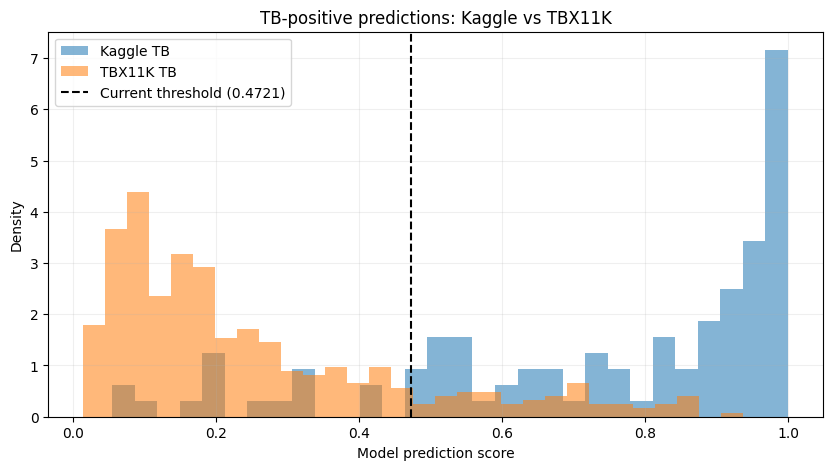

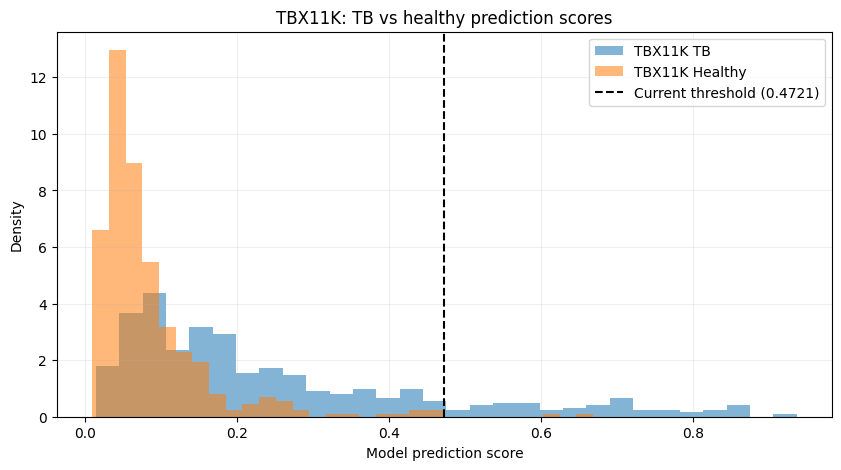


STEP 2 COMPLETE


In [ ]:


import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")
FILE = ROOT / "wide_mask_study/results/wide_seed52_predictions.npz"

with np.load(FILE) as data:
    y_val = data["yval"].ravel()
    p_val = data["pval"].ravel()

    y_ext = data["yexternal"].ravel()
    p_ext = data["pexternal"].ravel()

# Separate predictions according to actual labels
kaggle_tb = p_val[y_val == 1]
kaggle_normal = p_val[y_val == 0]

tbx_tb = p_ext[y_ext == 1]
tbx_normal = p_ext[y_ext == 0]

print("SEED 52 — PREDICTION ANALYSIS")
print("=" * 55)

def describe(name, scores):
    print(f"\n{name}")
    print(f"Images: {len(scores)}")
    print(f"Mean: {np.mean(scores):.4f}")
    print(f"Median: {np.median(scores):.4f}")
    print(f"Minimum: {np.min(scores):.4f}")
    print(f"Maximum: {np.max(scores):.4f}")
    print(f"25th percentile: {np.percentile(scores, 25):.4f}")
    print(f"75th percentile: {np.percentile(scores, 75):.4f}")

describe("Kaggle — TB", kaggle_tb)
describe("Kaggle — Normal", kaggle_normal)
describe("TBX11K — TB", tbx_tb)
describe("TBX11K — Healthy", tbx_normal)

# Plot 1: TB scores across datasets
plt.figure(figsize=(10, 5))

plt.hist(
    kaggle_tb,
    bins=30,
    alpha=0.55,
    density=True,
    label="Kaggle TB"
)

plt.hist(
    tbx_tb,
    bins=30,
    alpha=0.55,
    density=True,
    label="TBX11K TB"
)

plt.axvline(
    0.4721,
    color="black",
    linestyle="--",
    label="Current threshold (0.4721)"
)

plt.xlabel("Model prediction score")
plt.ylabel("Density")
plt.title("TB-positive predictions: Kaggle vs TBX11K")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Plot 2: TB vs healthy scores on TBX11K
plt.figure(figsize=(10, 5))

plt.hist(
    tbx_tb,
    bins=30,
    alpha=0.55,
    density=True,
    label="TBX11K TB"
)

plt.hist(
    tbx_normal,
    bins=30,
    alpha=0.55,
    density=True,
    label="TBX11K Healthy"
)

plt.axvline(
    0.4721,
    color="black",
    linestyle="--",
    label="Current threshold (0.4721)"
)

plt.xlabel("Model prediction score")
plt.ylabel("Density")
plt.title("TBX11K: TB vs healthy prediction scores")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("\nSTEP 2 COMPLETE")


All four files loaded.
External images: 800
TB: 400
Healthy: 400

NOTE: Matching labels do not prove matching image identities. Verify the saved dataset manifest separately.

THRESHOLD COMPARISON
         Model                   Strategy  Threshold  External AUC  Validation sensitivity  External sensitivity  External specificity  TP  FN  TN  FP
Original saved                     Youden     0.3485        0.8218                  0.8824                0.2075                0.9875  83 317 395   5
Original saved Validation 90% sensitivity     0.3068        0.8218                  0.9020                0.2300                0.9850  92 308 394   6
Original saved Validation 95% sensitivity     0.1642        0.8218                  0.9510                0.3950                0.9350 158 242 374  26
       Seed 42                     Youden     0.4304        0.7603                  0.8824                0.1325                0.9850  53 347 394   6
       Seed 42 Validation 90% sensitivity     0.3

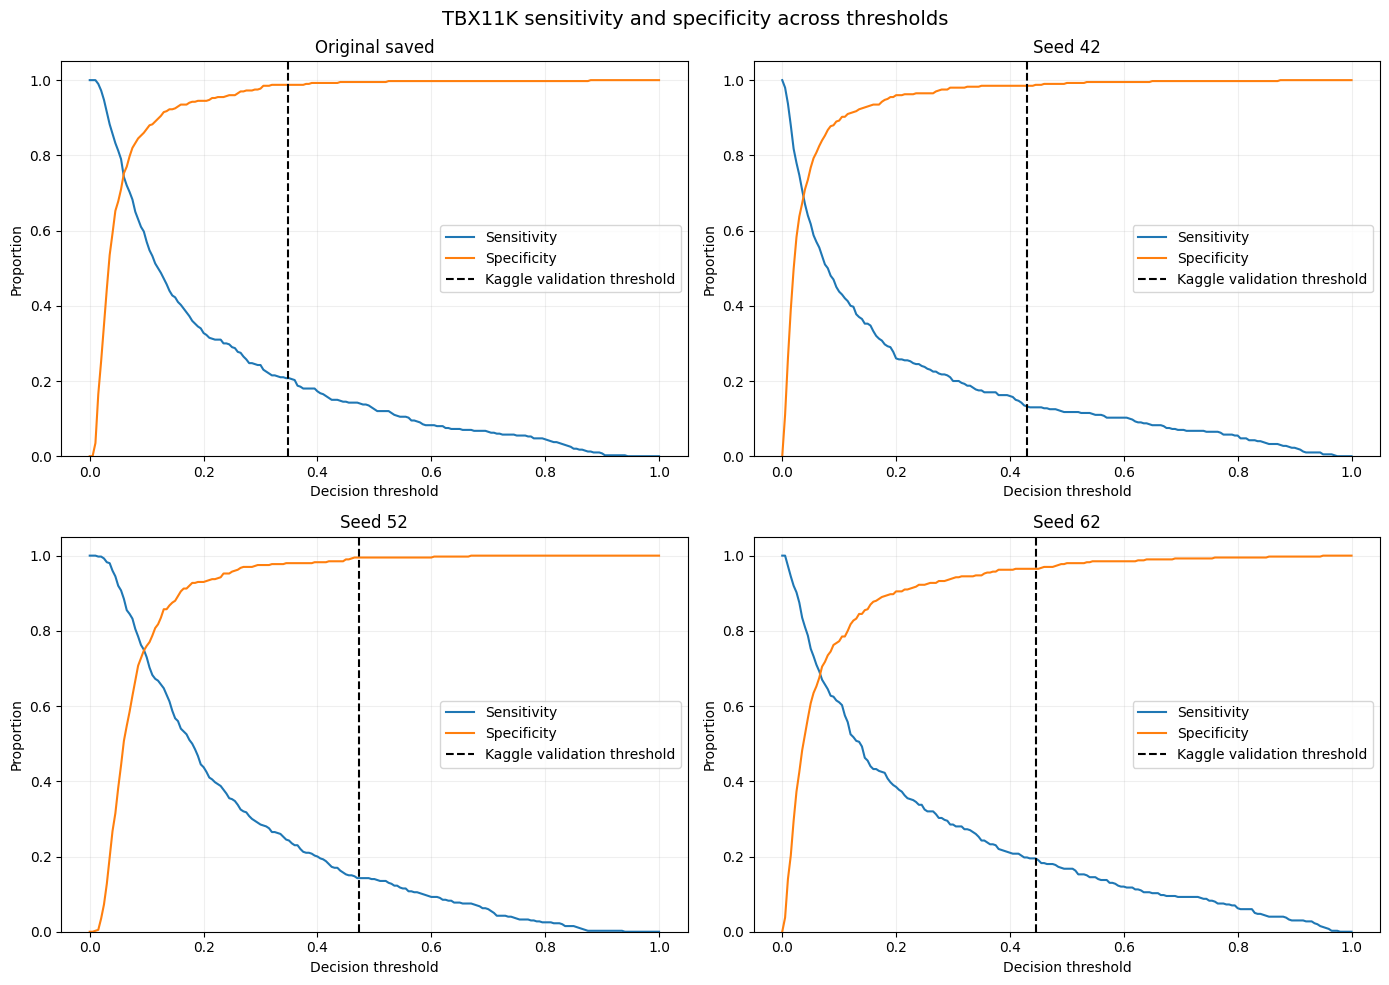

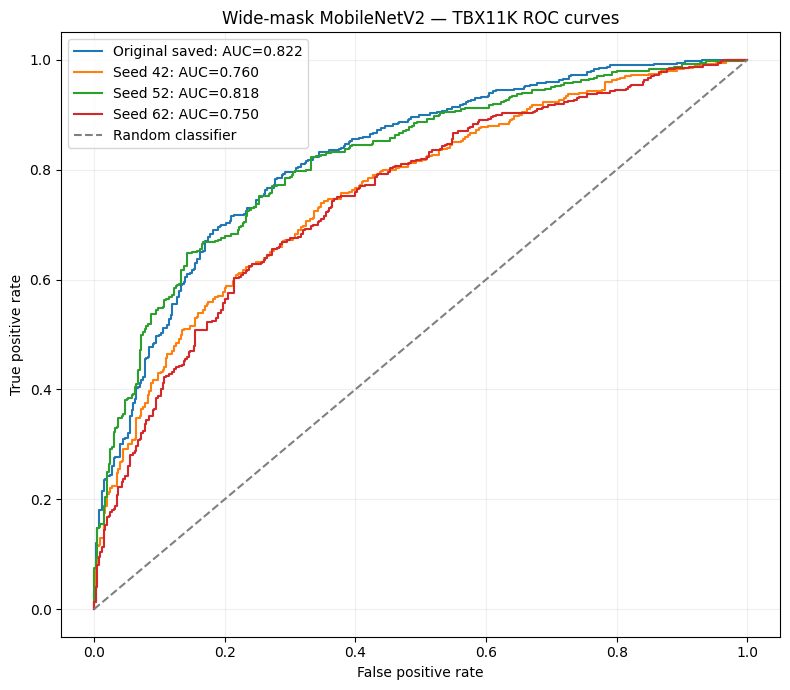

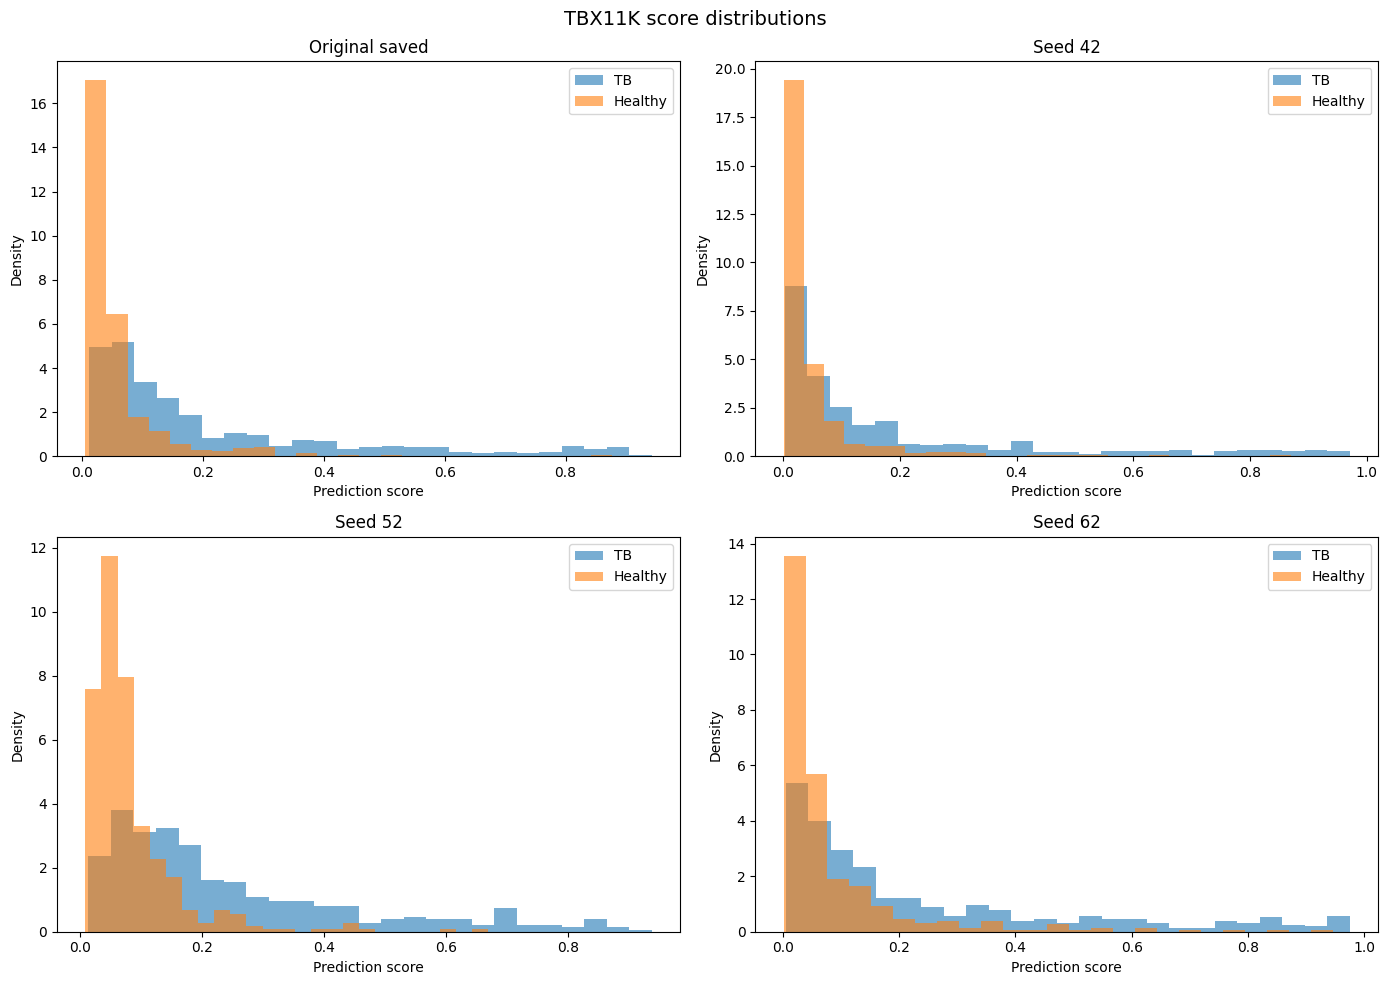


SEED 52 FALSE NEGATIVE ANALYSIS
Threshold: 0.4721
TB cases missed: 343

Lowest scoring missed TB cases:
 array_index  true_label  model_score  threshold
          75           1     0.013909   0.472094
         184           1     0.022918   0.472094
         190           1     0.024852   0.472094
         322           1     0.027106   0.472094
         163           1     0.027677   0.472094
         168           1     0.028570   0.472094
         200           1     0.029339   0.472094
         123           1     0.031502   0.472094
           6           1     0.035377   0.472094
         121           1     0.036018   0.472094
         281           1     0.036252   0.472094
          55           1     0.037089   0.472094
          46           1     0.037854   0.472094
          30           1     0.038170   0.472094
         195           1     0.038941   0.472094

DIAGNOSTICS COMPLETE
Results saved in:
/content/drive/MyDrive/EdgeTB_Project/wide_mask_study/results/sensitivi

In [ ]:

# ============================================================
# WIDE-MASK SENSITIVITY DIAGNOSTICS
# Uses existing predictions — no retraining required
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Locations and model files
# ------------------------------------------------------------

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")

RESULTS = ROOT / "wide_mask_study" / "results"
OUTPUT = RESULTS / "sensitivity_diagnostics"

OUTPUT.mkdir(parents=True, exist_ok=True)

FILES = {
    "Original saved": "wide_original_saved_predictions.npz",
    "Seed 42": "wide_seed42_predictions.npz",
    "Seed 52": "wide_seed52_predictions.npz",
    "Seed 62": "wide_seed62_predictions.npz"
}

# ------------------------------------------------------------
# 2. Load and validate predictions
# ------------------------------------------------------------

models = {}

for name, filename in FILES.items():

    path = RESULTS / filename

    if not path.exists():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as data:

        models[name] = {
            "yv": data["yval"].ravel().astype(int),
            "pv": data["pval"].ravel().astype(float),
            "ye": data["yexternal"].ravel().astype(int),
            "pe": data["pexternal"].ravel().astype(float)
        }

    d = models[name]

    for label_key, pred_key in [
        ("yv", "pv"),
        ("ye", "pe")
    ]:
        y = d[label_key]
        p = d[pred_key]

        assert len(y) == len(p), name
        assert set(np.unique(y)) == {0, 1}, name
        assert np.all(np.isfinite(p)), name
        assert np.all((p >= 0) & (p <= 1)), name

# Confirm the same label sequences were used.
reference = models["Original saved"]

for name, d in models.items():
    assert np.array_equal(d["ye"], reference["ye"]), (
        f"External label order differs: {name}"
    )
    assert np.array_equal(d["yv"], reference["yv"]), (
        f"Validation label order differs: {name}"
    )

print("All four files loaded.")
print("External images:", len(reference["ye"]))
print("TB:", np.sum(reference["ye"] == 1))
print("Healthy:", np.sum(reference["ye"] == 0))

print(
    "\nNOTE: Matching labels do not prove matching image "
    "identities. Verify the saved dataset manifest separately."
)

# ------------------------------------------------------------
# 3. Evaluation function
# ------------------------------------------------------------

def evaluate(y, p, threshold):

    predictions = (p >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, predictions, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    return {
        "threshold": threshold,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "TP": int(tp),
        "FN": int(fn),
        "TN": int(tn),
        "FP": int(fp)
    }

# ------------------------------------------------------------
# 4. Choose thresholds using KAGGLE VALIDATION ONLY
# ------------------------------------------------------------

def threshold_from_validation(y, p, method):

    fpr, tpr, thresholds = roc_curve(y, p)

    finite = np.isfinite(thresholds)

    if method == "youden":

        scores = tpr - fpr
        scores[~finite] = -np.inf

        idx = np.argmax(scores)

    else:

        target = float(method)

        eligible = np.where(
            (tpr >= target) & finite
        )[0]

        if len(eligible) == 0:
            raise ValueError(
                f"No threshold meets target {target}"
            )

        # Highest threshold meeting the requested
        # sensitivity on Kaggle validation.
        idx = eligible[
            np.argmax(thresholds[eligible])
        ]

    return float(thresholds[idx])

# ------------------------------------------------------------
# 5. Compare thresholds across all models
# ------------------------------------------------------------

rows = []

for name, d in models.items():

    auc = roc_auc_score(d["ye"], d["pe"])

    strategies = {
        "Youden":
            threshold_from_validation(
                d["yv"], d["pv"], "youden"
            ),

        "Validation 90% sensitivity":
            threshold_from_validation(
                d["yv"], d["pv"], 0.90
            ),

        "Validation 95% sensitivity":
            threshold_from_validation(
                d["yv"], d["pv"], 0.95
            )
    }

    for strategy, threshold in strategies.items():

        val = evaluate(
            d["yv"], d["pv"], threshold
        )

        ext = evaluate(
            d["ye"], d["pe"], threshold
        )

        rows.append({
            "Model": name,
            "Strategy": strategy,
            "Threshold": threshold,
            "External AUC": auc,
            "Validation sensitivity": val["sensitivity"],
            "External sensitivity": ext["sensitivity"],
            "External specificity": ext["specificity"],
            "TP": ext["TP"],
            "FN": ext["FN"],
            "TN": ext["TN"],
            "FP": ext["FP"]
        })

summary = pd.DataFrame(rows)

summary.to_csv(
    OUTPUT / "threshold_comparison.csv",
    index=False
)

print("\nTHRESHOLD COMPARISON")
print("=" * 75)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. Plot sensitivity and specificity vs threshold
#    TBX11K curve is exploratory, NOT threshold selection
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (name, d) in zip(axes.flat, models.items()):

    thresholds = np.linspace(0, 1, 201)

    sens = []
    spec = []

    for t in thresholds:

        e = evaluate(d["ye"], d["pe"], t)

        sens.append(e["sensitivity"])
        spec.append(e["specificity"])

    ax.plot(thresholds, sens, label="Sensitivity")
    ax.plot(thresholds, spec, label="Specificity")

    original_threshold = threshold_from_validation(
        d["yv"], d["pv"], "youden"
    )

    ax.axvline(
        original_threshold,
        linestyle="--",
        color="black",
        label="Kaggle validation threshold"
    )

    ax.set_title(name)
    ax.set_xlabel("Decision threshold")
    ax.set_ylabel("Proportion")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.2)
    ax.legend()

plt.suptitle(
    "TBX11K sensitivity and specificity across thresholds",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    OUTPUT / "threshold_tradeoffs.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 7. Compare external ROC curves
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

for name, d in models.items():

    fpr, tpr, _ = roc_curve(
        d["ye"], d["pe"]
    )

    auc = roc_auc_score(
        d["ye"], d["pe"]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name}: AUC={auc:.3f}"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Wide-mask MobileNetV2 — TBX11K ROC curves")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    OUTPUT / "external_roc_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. Score distribution comparison by model
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (name, d) in zip(axes.flat, models.items()):

    tb = d["pe"][d["ye"] == 1]
    normal = d["pe"][d["ye"] == 0]

    ax.hist(
        tb,
        bins=25,
        alpha=0.6,
        density=True,
        label="TB"
    )

    ax.hist(
        normal,
        bins=25,
        alpha=0.6,
        density=True,
        label="Healthy"
    )

    ax.set_title(name)
    ax.set_xlabel("Prediction score")
    ax.set_ylabel("Density")
    ax.legend()

plt.suptitle(
    "TBX11K score distributions",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    OUTPUT / "score_distributions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. Identify false negatives for seed 52
# ------------------------------------------------------------

name = "Seed 52"
d = models[name]

t = threshold_from_validation(
    d["yv"], d["pv"], "youden"
)

missed = np.where(
    (d["ye"] == 1) &
    (d["pe"] < t)
)[0]

false_negatives = pd.DataFrame({
    "array_index": missed,
    "true_label": d["ye"][missed],
    "model_score": d["pe"][missed],
    "threshold": t
})

false_negatives = false_negatives.sort_values(
    "model_score"
)

false_negatives.to_csv(
    OUTPUT / "seed52_false_negative_indices.csv",
    index=False
)

print("\nSEED 52 FALSE NEGATIVE ANALYSIS")
print("=" * 55)

print("Threshold:", round(t, 4))
print("TB cases missed:", len(missed))

print("\nLowest scoring missed TB cases:")
print(false_negatives.head(15).to_string(index=False))

# ------------------------------------------------------------
# 10. Complete
# ------------------------------------------------------------

print("\nDIAGNOSTICS COMPLETE")
print("Results saved in:")
print(OUTPUT)

print("\nGenerated files:")
for f in sorted(OUTPUT.iterdir()):
    print("-", f.name)


Available arrays: ['x', 'y', 'active']


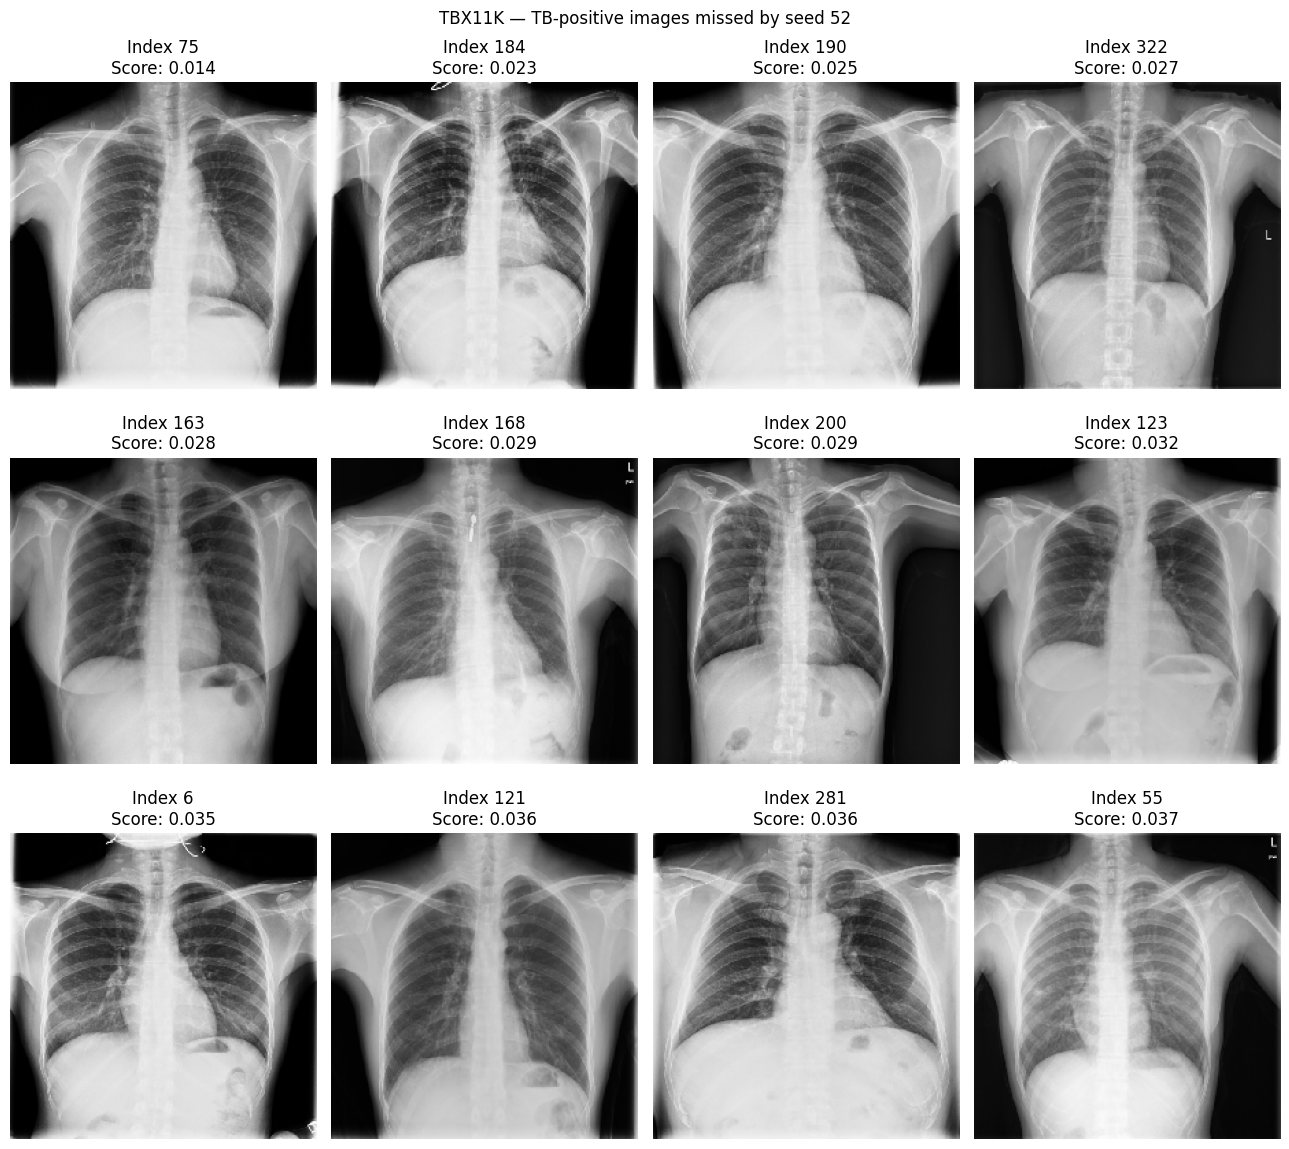

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

external_file = (
    ROOT / "results/tbx11k_eval_nearest.npz"
)

with np.load(external_file) as data:
    print("Available arrays:", data.files)

    images = data["x"]
    labels = data["y"]

d = models["Seed 52"]

# Verify dimensions and label ordering before linking
# predictions back to saved images.
assert len(images) == len(d["pe"])
assert np.array_equal(labels, d["ye"]), (
    "Labels do not match prediction order. "
    "Do not display images as false negatives."
)

threshold = threshold_from_validation(
    d["yv"], d["pv"], "youden"
)

missed = np.where(
    (d["ye"] == 1) &
    (d["pe"] < threshold)
)[0]

# Display 12 TB-positive images missed by the model.
# Sort by score so we inspect the lowest scoring cases.
missed = missed[np.argsort(d["pe"][missed])]

selected = missed[:12]

fig, axes = plt.subplots(
    3, 4, figsize=(13, 12)
)

for ax, idx in zip(axes.flat, selected):

    ax.imshow(images[idx], cmap="gray")
    ax.set_title(
        f"Index {idx}\nScore: {d['pe'][idx]:.3f}"
    )
    ax.axis("off")

plt.suptitle(
    "TBX11K — TB-positive images missed by seed 52"
)

plt.tight_layout()

plt.savefig(
    OUTPUT / "seed52_missed_tb_examples.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


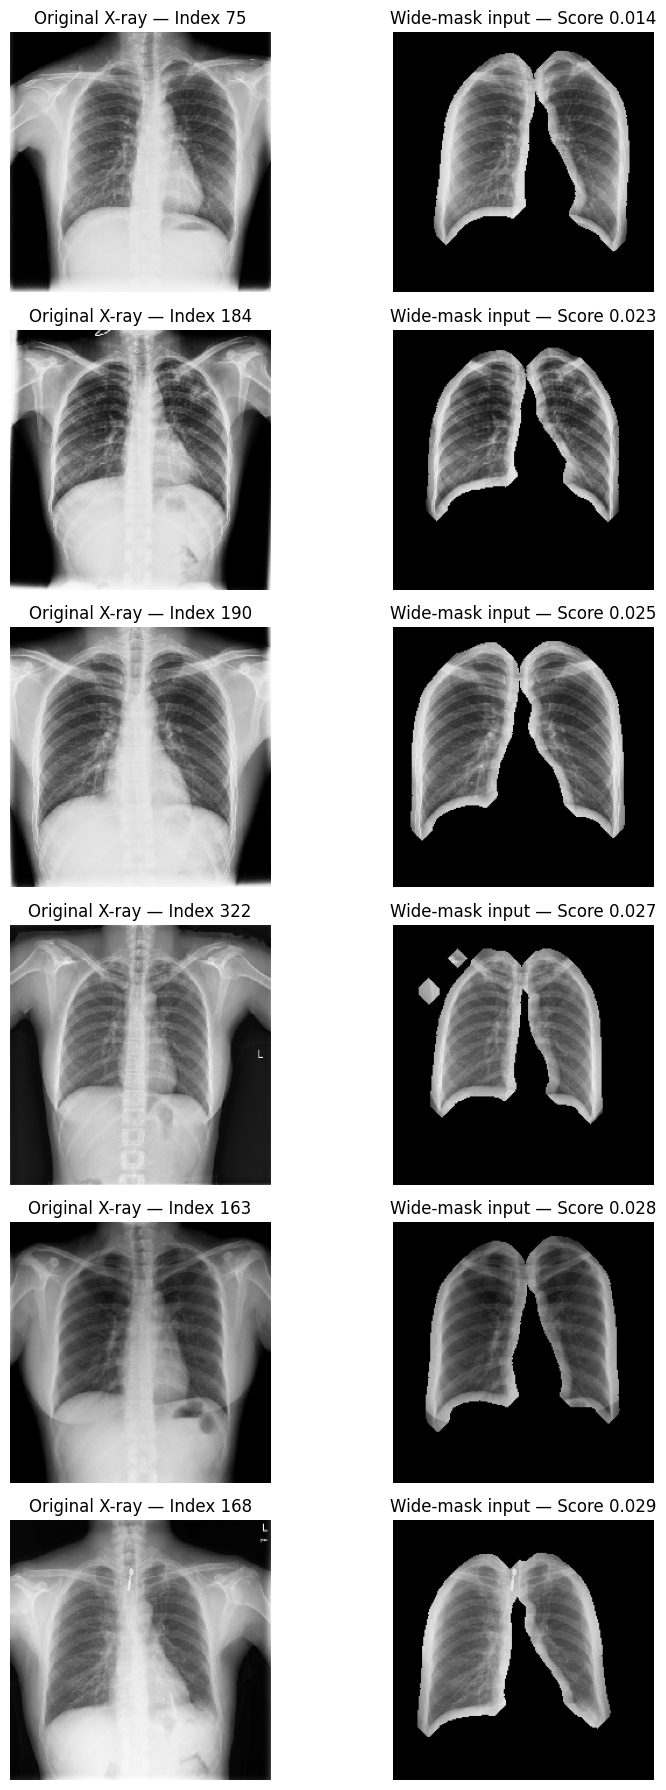

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")

# Original TBX11K evaluation images
with np.load(ROOT / "results/tbx11k_eval_nearest.npz") as data:
    original = data["x"].copy()
    labels = data["y"].copy()

# Wide-masked images actually supplied to the classifier
mask_path = (
    ROOT / "wide_mask_study/cache/"
    "external_wide_gray_uint8.npy"
)

masked = np.load(mask_path, mmap_mode="r")

# Seed 52 predictions
with np.load(
    ROOT / "wide_mask_study/results/"
    "wide_seed52_predictions.npz"
) as data:
    scores = data["pexternal"].copy()
    prediction_labels = data["yexternal"].copy()

assert len(original) == len(masked) == len(scores)
assert np.array_equal(labels, prediction_labels)

# Images with very low TB scores
indices = [75, 184, 190, 322, 163, 168]

fig, axes = plt.subplots(
    len(indices), 2,
    figsize=(9, 18)
)

for row, idx in enumerate(indices):

    axes[row, 0].imshow(original[idx])
    axes[row, 0].set_title(
        f"Original X-ray — Index {idx}"
    )

    axes[row, 1].imshow(
        masked[idx],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[row, 1].set_title(
        f"Wide-mask input — Score {scores[idx]:.3f}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path
import zipfile

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")

print("SEARCHING FOR TBX11K SOURCES")
print("=" * 50)

# Search likely project locations for original archives.
archives = [
    p for p in ROOT.rglob("*.zip")
    if "tbx" in p.name.lower()
]

for archive in archives:
    print("\nArchive:", archive)

    try:
        with zipfile.ZipFile(archive) as z:
            names = z.namelist()

            tb = [
                n for n in names
                if "/imgs/tb/" in "/" + n.lower()
                and n.lower().endswith((".png", ".jpg", ".jpeg"))
            ]

            healthy = [
                n for n in names
                if "/imgs/health/" in "/" + n.lower()
                and n.lower().endswith((".png", ".jpg", ".jpeg"))
            ]

            print("TB images:", len(tb))
            print("Healthy images:", len(healthy))
            print("Example TB files:", tb[:5])

    except (zipfile.BadZipFile, OSError) as exc:
        print("Could not inspect archive:", exc)

if not archives:
    print("No TBX11K ZIP archive found.")

# Check for extracted images.
for folder in [
    ROOT / "data_raw/tbx11k/TBX11K/imgs",
    ROOT / "datasets_external/tbx11k_test"
]:
    print("\nFolder:", folder)
    print("Exists:", folder.exists())

    if folder.exists():
        for sub in sorted(folder.iterdir()):
            if sub.is_dir():
                count = sum(
                    1 for p in sub.rglob("*")
                    if p.is_file()
                    and p.suffix.lower() in
                    {".png", ".jpg", ".jpeg"}
                )
                print(sub.name, ":", count)


SEARCHING FOR TBX11K SOURCES

Archive: /content/drive/MyDrive/EdgeTB_Project/data_raw/tbx11k.zip
TB images: 800
Healthy images: 3800
Example TB files: ['TBX11K/imgs/tb/tb0003.png', 'TBX11K/imgs/tb/tb0004.png', 'TBX11K/imgs/tb/tb0005.png', 'TBX11K/imgs/tb/tb0006.png', 'TBX11K/imgs/tb/tb0007.png']

Folder: /content/drive/MyDrive/EdgeTB_Project/data_raw/tbx11k/TBX11K/imgs
Exists: True
extra : 576
health : 3800
sick : 3800
tb : 800
test : 3302

Folder: /content/drive/MyDrive/EdgeTB_Project/datasets_external/tbx11k_test
Exists: True
Normal : 200
TB : 200


In [ ]:

from pathlib import Path
import numpy as np
import cv2
import hashlib

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")

SOURCE = ROOT / "data_raw/tbx11k/TBX11K/imgs"

EVAL_FILE = ROOT / "results/tbx11k_eval_nearest.npz"

with np.load(EVAL_FILE) as data:
    X = data["x"]
    y = data["y"]

print("Saved evaluation images:", len(X))
print("TB labels:", np.sum(y == 1))
print("Healthy labels:", np.sum(y == 0))

# Build image fingerprints for the source images.
# The saved evaluation arrays have been resized,
# so use the same target dimensions.
def fingerprint(image):
    image = np.asarray(image)

    if image.ndim == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    else:
        gray = image

    gray = cv2.resize(
        gray,
        (224, 224),
        interpolation=cv2.INTER_AREA
    )

    return hashlib.sha256(
        gray.astype(np.uint8).tobytes()
    ).hexdigest()

source_hashes = {}

for category, label in [("tb", 1), ("health", 0)]:

    folder = SOURCE / category

    for path in sorted(folder.glob("*.png")):

        img = cv2.imread(
            str(path),
            cv2.IMREAD_GRAYSCALE
        )

        if img is None:
            continue

        h = fingerprint(img)

        source_hashes.setdefault(h, []).append(
            (str(path), label)
        )

print("Source fingerprints:", len(source_hashes))

matched = 0
unmatched = 0
label_errors = 0

for i, image in enumerate(X):

    h = fingerprint(image)
    candidates = source_hashes.get(h, [])

    if not candidates:
        unmatched += 1
        continue

    matched += 1

    if not any(label == y[i] for _, label in candidates):
        label_errors += 1

print("\nMATCHING RESULTS")
print("Matched:", matched)
print("Unmatched:", unmatched)
print("Label mismatches:", label_errors)


Saved evaluation images: 800
TB labels: 400
Healthy labels: 400
Source fingerprints: 4600

MATCHING RESULTS
Matched: 0
Unmatched: 800
Label mismatches: 0


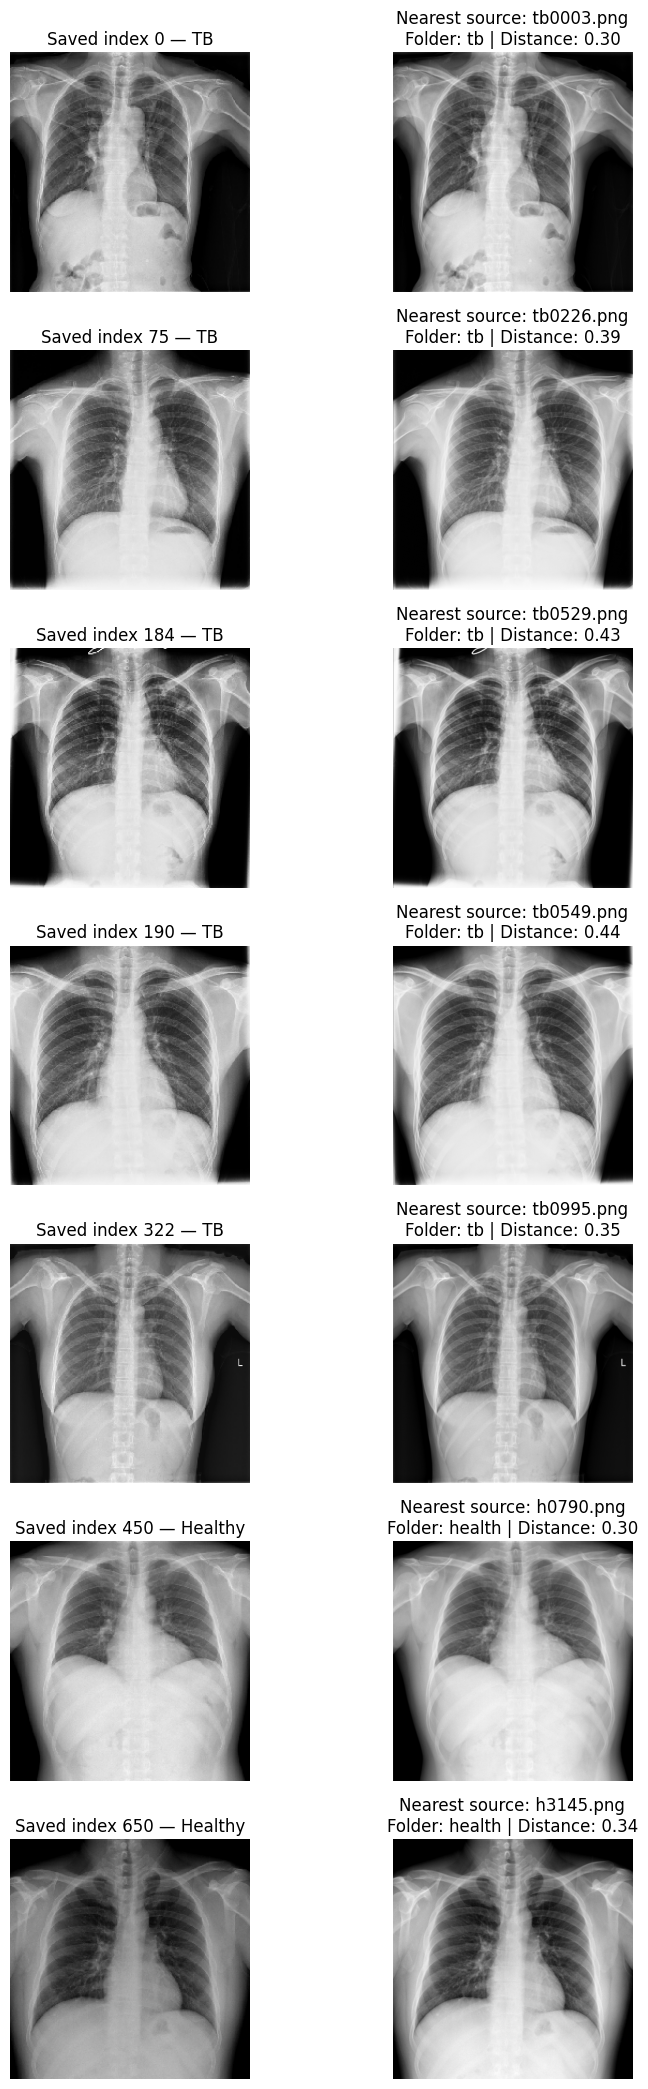

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.spatial.distance import cdist

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")
SOURCE = ROOT / "data_raw/tbx11k/TBX11K/imgs"
EVAL_FILE = ROOT / "results/tbx11k_eval_nearest.npz"

with np.load(EVAL_FILE) as data:
    X = data["x"]
    y = data["y"]

# Create a compact image representation for comparison.
def image_features(image):
    image = np.asarray(image)

    if image.ndim == 3:
        image = cv2.cvtColor(
            image.astype(np.uint8),
            cv2.COLOR_RGB2GRAY
        )

    image = cv2.resize(
        image,
        (32, 32),
        interpolation=cv2.INTER_AREA
    ).astype(np.float32)

    # Normalize appearance to reduce brightness differences.
    image -= image.mean()
    image /= image.std() + 1e-6

    return image.flatten()

# Build source features.
paths = sorted(
    list((SOURCE / "tb").glob("*.png")) +
    list((SOURCE / "health").glob("*.png"))
)

source_features = []

for path in paths:
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if img is not None:
        source_features.append(image_features(img))
    else:
        raise RuntimeError(f"Could not read: {path}")

source_features = np.stack(source_features)

# Inspect a few saved evaluation images.
sample_indices = [0, 75, 184, 190, 322, 450, 650]

fig, axes = plt.subplots(
    len(sample_indices), 2,
    figsize=(9, 3 * len(sample_indices))
)

for row, idx in enumerate(sample_indices):
    feature = image_features(X[idx])

    distances = cdist(
        feature[None, :],
        source_features,
        metric="euclidean"
    )[0]

    nearest = np.argmin(distances)
    path = paths[nearest]

    original = cv2.imread(
        str(path),
        cv2.IMREAD_GRAYSCALE
    )

    expected = "TB" if y[idx] == 1 else "Healthy"
    found = path.parent.name

    axes[row, 0].imshow(X[idx], cmap="gray")
    axes[row, 0].set_title(
        f"Saved index {idx} — {expected}"
    )

    axes[row, 1].imshow(original, cmap="gray")
    axes[row, 1].set_title(
        f"Nearest source: {path.name}\n"
        f"Folder: {found} | Distance: {distances[nearest]:.2f}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import cv2

from sklearn.neighbors import NearestNeighbors

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")

SOURCE = ROOT / "data_raw/tbx11k/TBX11K/imgs"
EVAL = ROOT / "results/tbx11k_eval_nearest.npz"

OUTPUT = ROOT / "wide_mask_study/results"
OUTPUT.mkdir(parents=True, exist_ok=True)

# Load saved evaluation images
with np.load(EVAL) as data:
    X = data["x"]
    y = data["y"]

def features(image):
    image = np.asarray(image)

    if image.ndim == 3:
        image = cv2.cvtColor(
            image.astype(np.uint8),
            cv2.COLOR_RGB2GRAY
        )

    image = cv2.resize(
        image,
        (32, 32),
        interpolation=cv2.INTER_AREA
    ).astype(np.float32)

    image -= image.mean()
    image /= image.std() + 1e-6

    return image.flatten()

# Read original images and retain their identity
paths = sorted(
    list((SOURCE / "tb").glob("*.png")) +
    list((SOURCE / "health").glob("*.png"))
)

source_features = []
valid_paths = []

for path in paths:
    image = cv2.imread(
        str(path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        continue

    source_features.append(features(image))
    valid_paths.append(path)

source_features = np.asarray(
    source_features,
    dtype=np.float32
)

saved_features = np.asarray(
    [features(image) for image in X],
    dtype=np.float32
)

# Get the two nearest original images
matcher = NearestNeighbors(
    n_neighbors=2,
    metric="euclidean",
    algorithm="brute",
    n_jobs=-1
)

matcher.fit(source_features)

distances, indices = matcher.kneighbors(
    saved_features
)

records = []

for i in range(len(X)):
    path = valid_paths[indices[i, 0]]

    saved_label = int(y[i])
    source_label = 1 if path.parent.name == "tb" else 0

    best_distance = float(distances[i, 0])
    second_distance = float(distances[i, 1])

    records.append({
        "array_index": i,
        "saved_label": saved_label,
        "source_filename": path.name,
        "source_folder": path.parent.name,
        "source_label": source_label,
        "label_agrees": saved_label == source_label,
        "distance": best_distance,
        "second_distance": second_distance,
        "distance_gap": second_distance - best_distance
    })

df = pd.DataFrame(records)

csv_path = OUTPUT / "tbx11k_image_identity_check.csv"
df.to_csv(csv_path, index=False)

print("DATASET IDENTITY CHECK")
print("=" * 50)

print("Saved images:", len(df))
print("Source images searched:", len(valid_paths))

print(
    "Nearest matches with agreeing labels:",
    df["label_agrees"].sum()
)

print(
    "Nearest matches with disagreeing labels:",
    (~df["label_agrees"]).sum()
)

print(
    "Unique matched source files:",
    df["source_filename"].nunique()
)

print("\nDISTANCE STATISTICS")
print(df["distance"].describe())

print("\nTEN MOST UNCERTAIN MATCHES")
print(
    df.sort_values(
        "distance",
        ascending=False
    ).head(10).to_string(index=False)
)

print("\nCSV saved to:")
print(csv_path)

print(
    "\nIMPORTANT: Nearest-neighbour matches are "
    "candidates, not automatic proof of identity. "
    "Review large distances, small distance gaps "
    "and duplicate source matches."
)


DATASET IDENTITY CHECK
Saved images: 800
Source images searched: 4600
Nearest matches with agreeing labels: 800
Nearest matches with disagreeing labels: 0
Unique matched source files: 800

DISTANCE STATISTICS
count    800.000000
mean       0.405779
std        0.183848
min        0.235088
25%        0.298644
50%        0.331951
75%        0.463001
max        1.567578
Name: distance, dtype: float64

TEN MOST UNCERTAIN MATCHES
 array_index  saved_label source_filename source_folder  source_label  label_agrees  distance  second_distance  distance_gap
         367            1      tb1115.png            tb             1          True  1.567578        18.049305     16.481727
         247            1      tb0758.png            tb             1          True  1.443021        11.216036      9.773014
           5            1      tb0014.png            tb             1          True  1.435087        11.834922     10.399835
          49            1      tb0142.png            tb             1   

In [ ]:

from pathlib import Path
import numpy as np

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")
CACHE = ROOT / "wide_mask_study" / "cache"

print("WIDE-MASK TRAINING CACHE")
print("=" * 50)

for path in sorted(CACHE.glob("*.npy")):
    arr = np.load(path, mmap_mode="r")

    print(f"\nFile: {path.name}")
    print("Shape:", arr.shape)
    print("Data type:", arr.dtype)
    print("Minimum:", arr.min())
    print("Maximum:", arr.max())

print("\nMODEL FILES")
print("=" * 50)

MODEL_DIRS = [
    ROOT / "wide_mask_study/models",
    ROOT / "model",
    ROOT / "models"
]

for folder in MODEL_DIRS:
    if folder.exists():
        for path in folder.glob("*.h5"):
            print(path)


WIDE-MASK TRAINING CACHE

File: external_wide_gray_uint8.npy
Shape: (800, 224, 224)
Data type: uint8
Minimum: 0
Maximum: 255

File: test_wide_gray_uint8.npy
Shape: (628, 224, 224)
Data type: uint8
Minimum: 0
Maximum: 255

File: train_wide_gray_uint8.npy
Shape: (2927, 224, 224)
Data type: uint8
Minimum: 0
Maximum: 255

File: val_wide_gray_uint8.npy
Shape: (627, 224, 224)
Data type: uint8
Minimum: 0
Maximum: 255

MODEL FILES
/content/drive/MyDrive/EdgeTB_Project/models/mobilenetv2_tb.h5
/content/drive/MyDrive/EdgeTB_Project/models/VGG16_tb.h5
/content/drive/MyDrive/EdgeTB_Project/models/mobilenetv2_segmented.h5
/content/drive/MyDrive/EdgeTB_Project/models/unet_lung.h5
/content/drive/MyDrive/EdgeTB_Project/models/mobilenetv2_clean_seed42.h5


In [ ]:

from pathlib import Path
import tensorflow as tf

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")

MODEL_DIR = ROOT / "wide_mask_study" / "models"

print("AVAILABLE WIDE-MASK MODELS")
print("=" * 50)

for path in sorted(MODEL_DIR.iterdir()):
    if path.is_file():
        print(
            path.name,
            "| Size:",
            round(path.stat().st_size / (1024 * 1024), 2),
            "MB"
        )

model_path = MODEL_DIR / "wide_seed52.keras"

assert model_path.exists(), (
    f"Model not found: {model_path}"
)

print("\nLOADING SEED 52...")

model = tf.keras.models.load_model(
    str(model_path),
    compile=False
)

print("\nMODEL INFORMATION")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total layers:", len(model.layers))
print("Total parameters:", model.count_params())

print("\nModel loaded successfully.")


AVAILABLE WIDE-MASK MODELS
wide_seed42.keras | Size: 9.18 MB
wide_seed52.keras | Size: 9.18 MB
wide_seed62.keras | Size: 9.18 MB

LOADING SEED 52...

MODEL INFORMATION
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Total layers: 157
Total parameters: 2259265

Model loaded successfully.


In [ ]:

# ============================================================
# EXPERIMENT: FINE-TUNE WIDE-MASK MOBILENETV2
# Starting checkpoint: wide_seed52.keras
# ============================================================

from pathlib import Path
import json
import random
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")
WORK = ROOT / "wide_mask_study"
CACHE = WORK / "cache"
MODELS = WORK / "models"
RESULTS = WORK / "results"

MODELS.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

SEED = 52
BATCH_SIZE = 16
EPOCHS = 15
LEARNING_RATE = 1e-5
UNFREEZE_LAST = 30

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# 1. Load cached wide-mask images
# ------------------------------------------------------------

Xtrain = np.load(
    CACHE / "train_wide_gray_uint8.npy",
    mmap_mode="r"
)

Xval = np.load(
    CACHE / "val_wide_gray_uint8.npy",
    mmap_mode="r"
)

# ------------------------------------------------------------
# 2. Rebuild labels in the same order as the caches
# ------------------------------------------------------------

CLEAN = ROOT / "datasets_clean"
EXTENSIONS = {".png", ".jpg", ".jpeg"}

def load_labels(split):
    labels = []

    for folder, label in [("Normal", 0), ("TB", 1)]:
        directory = CLEAN / split / folder
        assert directory.is_dir(), directory

        paths = sorted(
            p for p in directory.iterdir()
            if p.suffix.lower() in EXTENSIONS
        )

        labels.extend([label] * len(paths))

    return np.array(labels, dtype=np.int32)

ytrain = load_labels("train")
yval = load_labels("val")

assert len(Xtrain) == len(ytrain) == 2927
assert len(Xval) == len(yval) == 627

# Check validation order against previously saved predictions.
with np.load(
    RESULTS / "wide_seed52_predictions.npz"
) as old:
    assert np.array_equal(
        yval, old["yval"]
    ), "Validation labels/order differ. Stop before training."

print("Training images:", len(Xtrain))
print("Validation images:", len(Xval))
print("TB training images:", int(ytrain.sum()))
print("Normal training images:", int((ytrain == 0).sum()))

# ------------------------------------------------------------
# 3. Memory-efficient data loader
# ------------------------------------------------------------

class WideMaskSequence(tf.keras.utils.Sequence):

    def __init__(
        self, X, y,
        training=False,
        batch_size=16,
        seed=52,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.X = X
        self.y = np.asarray(y)
        self.training = training
        self.batch_size = batch_size

        self.order = np.arange(len(y))
        self.rng = np.random.default_rng(seed)

        self.augmentation = ImageDataGenerator(
            rotation_range=10,
            width_shift_range=0.05,
            height_shift_range=0.05,
            zoom_range=0.05,
            fill_mode="constant",
            cval=0
        )

        if training:
            self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.y) / self.batch_size))

    def __getitem__(self, index):

        ids = self.order[
            index * self.batch_size:
            (index + 1) * self.batch_size
        ]

        images = np.asarray(
            self.X[ids], dtype=np.float32
        ) / 255.0

        # Convert grayscale into three channels.
        images = np.repeat(
            images[..., None], 3, axis=-1
        )

        if self.training:
            for i in range(len(images)):
                images[i] = self.augmentation.random_transform(
                    images[i],
                    seed=int(self.rng.integers(0, 2**31 - 1))
                )

        return images, self.y[ids].astype(np.float32)

    def on_epoch_end(self):
        if self.training:
            self.rng.shuffle(self.order)


train_data = WideMaskSequence(
    Xtrain, ytrain,
    training=True,
    batch_size=BATCH_SIZE,
    seed=SEED
)

val_data = WideMaskSequence(
    Xval, yval,
    training=False,
    batch_size=BATCH_SIZE
)

# ------------------------------------------------------------
# 4. Load previously trained wide-mask classifier
# ------------------------------------------------------------

SOURCE_MODEL = MODELS / "wide_seed52.keras"

model = tf.keras.models.load_model(
    str(SOURCE_MODEL),
    compile=False
)

# ------------------------------------------------------------
# 5. Unfreeze only deeper layers
# ------------------------------------------------------------

model.trainable = True

for layer in model.layers:
    layer.trainable = False

# Allow the final 30 layers to update.
for layer in model.layers[-UNFREEZE_LAST:]:
    if not isinstance(
        layer, tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True

# Ensure the final classification layer is trainable.
model.layers[-1].trainable = True

print("\nMODEL FINE-TUNING CONFIGURATION")
print("=" * 50)

trainable_layers = [
    layer.name
    for layer in model.layers
    if layer.trainable
]

print("Total layers:", len(model.layers))
print("Trainable layers:", len(trainable_layers))
print("Trainable parameters:",
      sum(int(np.prod(w.shape))
          for w in model.trainable_weights))
print("Last trainable layers:", trainable_layers[-10:])

# ------------------------------------------------------------
# 6. Compile with a small learning rate
# ------------------------------------------------------------

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

# Balance TB and Normal classes.
n_tb = int(ytrain.sum())
n_normal = int((ytrain == 0).sum())

class_weights = {
    0: len(ytrain) / (2 * n_normal),
    1: len(ytrain) / (2 * n_tb)
}

print("Class weights:", class_weights)

# ------------------------------------------------------------
# 7. Save best checkpoint
# ------------------------------------------------------------

SAVE_PATH = MODELS / "wide_seed52_finetuned.keras"

callbacks = [
    ModelCheckpoint(
        str(SAVE_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    )
]

# ------------------------------------------------------------
# 8. Start fine-tuning
# ------------------------------------------------------------

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=2
)

# Save training history.
history_path = RESULTS / "wide_seed52_finetuned_history.json"

history_path.write_text(
    json.dumps(
        {
            key: [float(value) for value in values]
            for key, values in history.history.items()
        },
        indent=2
    )
)

print("\nFINE-TUNING COMPLETE")
print("Model saved to:", SAVE_PATH)
print("History saved to:", history_path)


Training images: 2927
Validation images: 627
TB training images: 477
Normal training images: 2450

MODEL FINE-TUNING CONFIGURATION
Total layers: 157
Trainable layers: 21
Trainable parameters: 1358401
Last trainable layers: ['block_16_expand', 'block_16_expand_relu', 'block_16_depthwise', 'block_16_depthwise_relu', 'block_16_project', 'Conv_1', 'out_relu', 'global_average_pooling2d', 'dropout', 'dense']
Class weights: {0: 0.5973469387755102, 1: 3.0681341719077566}
Epoch 1/15

Epoch 1: val_loss improved from None to 0.30168, saving model to /content/drive/MyDrive/EdgeTB_Project/wide_mask_study/models/wide_seed52_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/EdgeTB_Project/wide_mask_study/models/wide_seed52_finetuned.keras
183/183 - 158s - 861ms/step - auc: 0.9546 - loss: 0.2698 - recall: 0.8847 - val_auc: 0.9487 - val_loss: 0.3017 - val_recall: 0.8824
Epoch 2/15

Epoch 2: val_loss improved from 0.30168 to 0.27141, saving model to /content/drive/MyDrive/EdgeTB_

In [ ]:

# ============================================================
# EVALUATE FINE-TUNED MODEL
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

# Load fine-tuned checkpoint.
fine_model = tf.keras.models.load_model(
    str(SAVE_PATH),
    compile=False
)

# Use the existing cached validation, test and external images.
Xtest = np.load(
    CACHE / "test_wide_gray_uint8.npy",
    mmap_mode="r"
)

Xexternal = np.load(
    CACHE / "external_wide_gray_uint8.npy",
    mmap_mode="r"
)

ytest = load_labels("test")

with np.load(
    ROOT / "results/tbx11k_eval_nearest.npz"
) as external_data:
    yexternal = external_data["y"].astype(int)

assert len(Xtest) == len(ytest) == 628
assert len(Xexternal) == len(yexternal) == 800

# Confirm label order against saved seed 52 results.
with np.load(
    RESULTS / "wide_seed52_predictions.npz"
) as old:
    assert np.array_equal(ytest, old["ytest"])
    assert np.array_equal(yexternal, old["yexternal"])

    baseline_val = old["pval"].copy()
    baseline_test = old["ptest"].copy()
    baseline_external = old["pexternal"].copy()

def predict_cached(model, X, batch_size=32):
    output = []

    for start in range(0, len(X), batch_size):
        batch = np.asarray(
            X[start:start + batch_size],
            dtype=np.float32
        ) / 255.0

        batch = np.repeat(
            batch[..., None],
            3,
            axis=-1
        )

        scores = model.predict(
            batch, verbose=0
        ).reshape(-1)

        output.append(scores)

    return np.concatenate(output)

print("Generating fine-tuned predictions...")

pval_fine = predict_cached(fine_model, Xval)
ptest_fine = predict_cached(fine_model, Xtest)
pext_fine = predict_cached(fine_model, Xexternal)

# ------------------------------------------------------------
# Select thresholds using KAGGLE VALIDATION only.
# ------------------------------------------------------------

def select_threshold(y, scores, target=None):
    fpr, tpr, thresholds = roc_curve(y, scores)

    finite = np.isfinite(thresholds)

    if target is None:
        objective = np.where(
            finite, tpr - fpr, -np.inf
        )
        idx = np.argmax(objective)

    else:
        eligible = np.where(
            finite & (tpr >= target)
        )[0]

        if not len(eligible):
            raise ValueError("No eligible threshold.")

        # Highest threshold reaching the target.
        idx = eligible[
            np.argmax(thresholds[eligible])
        ]

    return float(thresholds[idx])

def metrics(y, scores, threshold):
    pred = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    return {
        "AUC": roc_auc_score(y, scores),
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "TP": int(tp),
        "FN": int(fn),
        "TN": int(tn),
        "FP": int(fp)
    }

comparison = []

runs = {
    "Original seed 52": (
        baseline_val,
        baseline_test,
        baseline_external
    ),
    "Fine-tuned seed 52": (
        pval_fine,
        ptest_fine,
        pext_fine
    )
}

for name, (pv, pt, pe) in runs.items():

    thresholds = {
        "Youden": select_threshold(yval, pv),
        "Validation 90%": select_threshold(
            yval, pv, 0.90
        ),
        "Validation 95%": select_threshold(
            yval, pv, 0.95
        )
    }

    for strategy, threshold in thresholds.items():

        for dataset, labels, scores in [
            ("Kaggle test", ytest, pt),
            ("TBX11K", yexternal, pe)
        ]:
            results = metrics(
                labels, scores, threshold
            )

            comparison.append({
                "Model": name,
                "Dataset": dataset,
                "Threshold strategy": strategy,
                "Threshold": threshold,
                **results
            })

df = pd.DataFrame(comparison)

csv_path = (
    RESULTS /
    "wide_seed52_finetuning_comparison.csv"
)

df.to_csv(csv_path, index=False)

print("\nFINE-TUNING RESULTS")
print("=" * 75)

print(
    df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# Save predictions for future analysis.
np.savez_compressed(
    RESULTS / "wide_seed52_finetuned_predictions.npz",
    yval=yval,
    pval=pval_fine,
    ytest=ytest,
    ptest=ptest_fine,
    yexternal=yexternal,
    pexternal=pext_fine
)

print("\nResults saved to:", csv_path)


Generating fine-tuned predictions...

FINE-TUNING RESULTS
             Model     Dataset Threshold strategy  Threshold    AUC  Sensitivity  Specificity  TP  FN  TN  FP
  Original seed 52 Kaggle test             Youden     0.4721 0.9258       0.8058       0.8781  83  20 461  64
  Original seed 52      TBX11K             Youden     0.4721 0.8182       0.1425       0.9950  57 343 398   2
  Original seed 52 Kaggle test     Validation 90%     0.3137 0.9258       0.8738       0.7943  90  13 417 108
  Original seed 52      TBX11K     Validation 90%     0.3137 0.8182       0.2750       0.9750 110 290 390  10
  Original seed 52 Kaggle test     Validation 95%     0.2046 0.9258       0.9515       0.6686  98   5 351 174
  Original seed 52      TBX11K     Validation 95%     0.2046 0.8182       0.4250       0.9325 170 230 373  27
Fine-tuned seed 52 Kaggle test             Youden     0.4315 0.9837       0.8641       0.9657  89  14 507  18
Fine-tuned seed 52      TBX11K             Youden     0.4315 0

In [2]:

from pathlib import Path
from collections import Counter
import zipfile

# Mount Google Drive if needed
from google.colab import drive
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")

SHENZHEN_ZIP = (
    ROOT / "datasets" / "shenzhen" / "archive (7).zip"
)

print("SHENZHEN DATASET INSPECTION")
print("=" * 55)

assert SHENZHEN_ZIP.exists(), (
    f"Archive not found: {SHENZHEN_ZIP}"
)

print("Archive:", SHENZHEN_ZIP.name)
print(
    "Size:",
    round(SHENZHEN_ZIP.stat().st_size / 1e9, 2),
    "GB"
)

with zipfile.ZipFile(SHENZHEN_ZIP) as archive:

    names = [
        info.filename
        for info in archive.infolist()
        if not info.is_dir()
    ]

    images = [
        name for name in names
        if name.lower().endswith(
            (".png", ".jpg", ".jpeg", ".bmp")
        )
    ]

    print("\nTotal files:", len(names))
    print("Image files:", len(images))

    print("\nFILE TYPES")
    extensions = Counter(
        Path(name).suffix.lower()
        for name in names
    )

    for extension, count in extensions.most_common():
        print(extension or "(no extension)", count)

    print("\nTOP-LEVEL FOLDERS")
    folders = Counter(
        name.split("/")[0]
        for name in names
    )

    for folder, count in folders.most_common(15):
        print(folder, count)

    print("\nFIRST 25 IMAGE PATHS")
    for name in images[:25]:
        print(name)

    print("\nFIRST 15 NON-IMAGE FILES")
    for name in [
        n for n in names if n not in set(images)
    ][:15]:
        print(name)

print("\nInspection complete. No files were extracted.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SHENZHEN DATASET INSPECTION
Archive: archive (7).zip
Size: 3.77 GB

Total files: 663
Image files: 662

FILE TYPES
.png 662
.csv 1

TOP-LEVEL FOLDERS
images 662
shenzhen_metadata.csv 1

FIRST 25 IMAGE PATHS
images/images/CHNCXR_0001_0.png
images/images/CHNCXR_0002_0.png
images/images/CHNCXR_0003_0.png
images/images/CHNCXR_0004_0.png
images/images/CHNCXR_0005_0.png
images/images/CHNCXR_0006_0.png
images/images/CHNCXR_0007_0.png
images/images/CHNCXR_0008_0.png
images/images/CHNCXR_0009_0.png
images/images/CHNCXR_0010_0.png
images/images/CHNCXR_0011_0.png
images/images/CHNCXR_0012_0.png
images/images/CHNCXR_0013_0.png
images/images/CHNCXR_0014_0.png
images/images/CHNCXR_0015_0.png
images/images/CHNCXR_0016_0.png
images/images/CHNCXR_0017_0.png
images/images/CHNCXR_0018_0.png
images/images/CHNCXR_0019_0.png
images/images/CHNCXR_0020_0.png
images/images/CHNCXR_0021

In [3]:

from pathlib import Path
from collections import Counter
import zipfile
import pandas as pd
from io import BytesIO

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")

ZIP_PATH = (
    ROOT / "datasets/shenzhen/archive (7).zip"
)

print("SHENZHEN METADATA CHECK")
print("=" * 55)

with zipfile.ZipFile(ZIP_PATH) as z:

    # Read the metadata directly from the ZIP.
    metadata = pd.read_csv(
        BytesIO(z.read("shenzhen_metadata.csv"))
    )

    image_names = {
        Path(name).name.lower()
        for name in z.namelist()
        if name.lower().endswith(".png")
    }

print("\nMetadata shape:", metadata.shape)
print("\nMetadata columns:")
print(metadata.columns.tolist())

print("\nFirst five metadata rows:")
print(metadata.head(5).to_string(index=False))

print("\nImage count:", len(image_names))

print("\nFilename label suffixes:")
print(Counter(
    Path(name).stem.rsplit("_", 1)[-1]
    for name in image_names
))

# Check exact filename overlap with existing local datasets.
print("\nEXACT FILENAME OVERLAP CHECK")
print("=" * 55)

folders_to_check = [
    ROOT / "datasets_clean",
    ROOT / "datasets",
    ROOT / "datasets_external",
    ROOT / "data_raw/tbx11k/TBX11K/imgs"
]

for folder in folders_to_check:

    if not folder.exists():
        continue

    existing_names = {
        path.name.lower()
        for path in folder.rglob("*")
        if path.is_file()
        and path.suffix.lower()
        in {".png", ".jpg", ".jpeg"}
    }

    overlap = image_names.intersection(
        existing_names
    )

    print(f"\nFolder: {folder.name}")
    print("Images checked:", len(existing_names))
    print("Exact filename overlaps:", len(overlap))

    if overlap:
        print("Examples:", sorted(overlap)[:10])

print("\nMetadata inspection complete.")


SHENZHEN METADATA CHECK

Metadata shape: (662, 4)

Metadata columns:
['study_id', 'sex', 'age', 'findings']

First five metadata rows:
         study_id    sex  age findings
CHNCXR_0001_0.png   Male   45   normal
CHNCXR_0002_0.png   Male   63   normal
CHNCXR_0003_0.png Female   48   normal
CHNCXR_0004_0.png   Male   58   normal
CHNCXR_0005_0.png   Male   28   normal

Image count: 662

Filename label suffixes:
Counter({'1': 336, '0': 326})

EXACT FILENAME OVERLAP CHECK

Folder: datasets_clean
Images checked: 4182
Exact filename overlaps: 0

Folder: datasets
Images checked: 4338
Exact filename overlaps: 0

Folder: datasets_external
Images checked: 400
Exact filename overlaps: 0

Folder: imgs
Images checked: 12278
Exact filename overlaps: 327
Examples: ['chncxr_0002_0.png', 'chncxr_0004_0.png', 'chncxr_0007_0.png', 'chncxr_0009_0.png', 'chncxr_0010_0.png', 'chncxr_0011_0.png', 'chncxr_0013_0.png', 'chncxr_0016_0.png', 'chncxr_0018_0.png', 'chncxr_0019_0.png']

Metadata inspection complete

In [4]:

from pathlib import Path
from collections import Counter, defaultdict
import zipfile

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")

SHENZHEN_ZIP = ROOT / "datasets/shenzhen/archive (7).zip"
TBX = ROOT / "data_raw/tbx11k/TBX11K/imgs"

with zipfile.ZipFile(SHENZHEN_ZIP) as z:
    shenzhen_names = {
        Path(n).name.lower()
        for n in z.namelist()
        if n.lower().endswith(".png")
    }

overlaps_by_folder = defaultdict(list)

for path in TBX.rglob("*"):
    if not path.is_file():
        continue

    if path.name.lower() in shenzhen_names:
        relative = path.relative_to(TBX)

        # First directory under TBX11K/imgs
        folder = relative.parts[0]

        overlaps_by_folder[folder].append(path)

print("SHENZHEN OVERLAP BY TBX11K FOLDER")
print("=" * 55)

total = 0

for folder, paths in sorted(overlaps_by_folder.items()):
    print(f"\nFolder: {folder}")
    print("Matching filenames:", len(paths))

    for path in paths[:8]:
        print(" ", path.relative_to(TBX))

    total += len(paths)

print("\nTotal overlapping file paths:", total)

unique_names = {
    path.name.lower()
    for paths in overlaps_by_folder.values()
    for path in paths
}

print("Unique overlapping filenames:", len(unique_names))
print("Shenzhen filenames not found in TBX11K:",
      len(shenzhen_names - unique_names))

# Check for same filenames in separate TBX11K folders.
duplicates = Counter(
    path.name.lower()
    for paths in overlaps_by_folder.values()
    for path in paths
)

print(
    "Overlapping filenames occurring more than once:",
    sum(count > 1 for count in duplicates.values())
)


SHENZHEN OVERLAP BY TBX11K FOLDER

Folder: extra
Matching filenames: 327
  extra/mc+shenzhen/train/CHNCXR_0010_0.png
  extra/mc+shenzhen/train/CHNCXR_0004_0.png
  extra/mc+shenzhen/train/CHNCXR_0020_0.png
  extra/mc+shenzhen/train/CHNCXR_0019_0.png
  extra/mc+shenzhen/train/CHNCXR_0011_0.png
  extra/mc+shenzhen/train/CHNCXR_0025_0.png
  extra/mc+shenzhen/train/CHNCXR_0026_0.png
  extra/mc+shenzhen/train/CHNCXR_0033_0.png

Total overlapping file paths: 327
Unique overlapping filenames: 327
Shenzhen filenames not found in TBX11K: 335
Overlapping filenames occurring more than once: 0


In [5]:

import zipfile
import cv2
import numpy as np
from pathlib import Path
from collections import Counter

ROOT = Path("/content/drive/MyDrive/EdgeTB_Project")

ZIP_PATH = ROOT / "datasets/shenzhen/archive (7).zip"
TBX = ROOT / "data_raw/tbx11k/TBX11K/imgs"

# Only folders proposed for classifier development.
CATEGORIES = ["tb", "health", "sick"]

def fingerprint(image_bytes=None, path=None):
    if image_bytes is not None:
        array = np.frombuffer(image_bytes, dtype=np.uint8)
        image = cv2.imdecode(array, cv2.IMREAD_GRAYSCALE)
    else:
        image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise ValueError(f"Image could not be decoded: {path}")

    image = cv2.resize(
        image, (32, 32),
        interpolation=cv2.INTER_AREA
    ).astype(np.float32)

    image -= image.mean()
    image /= image.std() + 1e-6

    return image.flatten()

print("BUILDING TBX11K IMAGE FEATURES")

tbx_paths = []
tbx_features = []

for category in CATEGORIES:
    for path in sorted((TBX / category).glob("*.png")):
        tbx_paths.append(path)
        tbx_features.append(fingerprint(path=path))

tbx_features = np.stack(tbx_features)

print("TBX11K images:", len(tbx_paths))

print("\nPROCESSING SHENZHEN IMAGES")

shenzhen_names = []
shenzhen_features = []

with zipfile.ZipFile(ZIP_PATH) as archive:
    names = [
        name for name in archive.namelist()
        if name.lower().endswith(".png")
    ]

    for name in names:
        image_bytes = archive.read(name)

        shenzhen_names.append(Path(name).name)
        shenzhen_features.append(
            fingerprint(image_bytes=image_bytes)
        )

shenzhen_features = np.stack(shenzhen_features)

print("Shenzhen images:", len(shenzhen_names))

# Nearest image matches.
from sklearn.neighbors import NearestNeighbors

matcher = NearestNeighbors(
    n_neighbors=2,
    metric="euclidean",
    algorithm="brute",
    n_jobs=-1
)

matcher.fit(tbx_features)

distances, indices = matcher.kneighbors(
    shenzhen_features
)

print("\nTEN CLOSEST IMAGE PAIRS")
print("=" * 60)

for i in np.argsort(distances[:, 0])[:10]:
    print(
        shenzhen_names[i],
        "<->",
        tbx_paths[indices[i, 0]].name,
        "| Distance:",
        round(float(distances[i, 0]), 4)
    )

print("\nDISTANCE SUMMARY")
print(
    "Minimum:", float(distances[:, 0].min()),
    "\nMedian:", float(np.median(distances[:, 0])),
    "\nMaximum:", float(distances[:, 0].max())
)

print("\nIMPORTANT: Low distance identifies possible")
print("duplicates, not automatically confirmed duplicates.")


BUILDING TBX11K IMAGE FEATURES
TBX11K images: 8400

PROCESSING SHENZHEN IMAGES
Shenzhen images: 662

TEN CLOSEST IMAGE PAIRS
CHNCXR_0149_0.png <-> h4418.png | Distance: 7.7555
CHNCXR_0268_0.png <-> h4286.png | Distance: 8.1686
CHNCXR_0159_0.png <-> h0519.png | Distance: 8.1788
CHNCXR_0104_0.png <-> h4169.png | Distance: 8.213
CHNCXR_0209_0.png <-> h2217.png | Distance: 8.3344
CHNCXR_0130_0.png <-> h2618.png | Distance: 8.4337
CHNCXR_0501_1.png <-> h1683.png | Distance: 8.5779
CHNCXR_0188_0.png <-> h2314.png | Distance: 8.6529
CHNCXR_0567_1.png <-> h2743.png | Distance: 8.6989
CHNCXR_0436_1.png <-> h2633.png | Distance: 8.722

DISTANCE SUMMARY
Minimum: 7.755459785461426 
Median: 12.141788005828857 
Maximum: 25.809036254882812

IMPORTANT: Low distance identifies possible
duplicates, not automatically confirmed duplicates.
